In [54]:
# same as ./zzzz/superpixel_RF_data3.ipynb

In [ ]:
# ★config
import os, re, glob

# image path
data_root = "/home/kmanabe2403/document/dune/superpixel/data_sample"
target_root = os.path.join(data_root, "mag500")
target_plates = {
    "old": ["pl01", "pl02", "pl04"],
    "new": ["pl01", "pl02", "pl04"]
    # "old": ["pl01", "pl02", "pl04", "pl07", "pl08", "pl09", "pl11", "pl13", "pl14", "pl15", "pl17", "pl18", "pl19", "pl21", "pl22", "pl23", "pl24", "pl27"],
    # "new": ["pl01", "pl02", "pl04", "pl05", "pl06", "pl07", "pl08", "pl09", "pl10", "pl11", "pl12", "pl13", "pl14", "pl15", "pl16", "pl17", "pl18", "pl19"]
}
images_per_plate = 3

# dir
path_for_data = os.path.join(data_root, "pipeline_output_sample")
image_save_dir = os.path.join(path_for_data, "images")
segment_save_dir = os.path.join(path_for_data, "segments")
feature_save_dir = os.path.join(path_for_data, "features")
result_dir = os.path.join(path_for_data, "RF_results")
for d in [image_save_dir, segment_save_dir, feature_save_dir, result_dir]:
    os.makedirs(d, exist_ok=True)

# superpixel param
param_n_segments = 300
param_compactness = 10.0

# model
model_paths = "validation3/training3_low/stage1_GMM/data3/RFmodel_step1/rf_stage1_All_grouped_GMM0.70.pkl"
stage2_model_paths = {
    "1": "validation3/training3_low/stage1_GMM/data3/RFmodel_step2_group2/rf_stage1_All_grouped_GMM0.70.pkl",
    "2": "validation3/training3_low/stage1_GMM/data3/RFmodel_step2_group3/rf_stage1_All_grouped_GMM0.70.pkl",
    "3": "validation3/training3_low/stage1_GMM/data3/RFmodel_step2_group4/rf_stage1_All_grouped_GMM0.70.pkl"
}
stage3_model_paths = {
    "20": "validation3/training3_low/stage1_GMM/data3/RFmodel_step3_group31/rf_stage1_All_grouped_GMM0.70.pkl"
}


def natural_sort_key(path):
    filename = os.path.basename(path)
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', filename)]
image_paths = []
for group, plates in target_plates.items():
    for plate in plates:
        plate_dir = os.path.join(target_root, group, plate)
        paths = sorted(glob.glob(os.path.join(plate_dir, "*.jpg")), key=natural_sort_key)[:images_per_plate]
        for path in paths:
            image_paths.append({"path": path, "group": group, "plate": plate, "name": os.path.splitext(os.path.basename(path))[0]})

print(f"Total images: {len(image_paths)}")
# for i, item in enumerate(image_paths):
    # print(i, item["group"], item["plate"], item["name"])

Total images: 18


In [ ]:
# crop & superpixel: process and save one image at a time
import csv, gc, json, os
from pathlib import Path
import numpy as np
from skimage import io, __version__ as skimage_version
from skimage.color import rgb2lab
from skimage.segmentation import slic

crop_params = {"top": 60, "bottom": 100, "left": 60, "right": 100}
overwrite_preprocessing = False  # True: recalculate every image

def save_preprocess_npy(path, array):
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("wb") as f:
        np.save(f, array, allow_pickle=False)
    os.replace(temporary, path)

def preprocess_one_image(image_id, item, output_dir, n_segments, compactness, crop, overwrite):
    source = Path(item["path"]).resolve()
    stat = source.stat()
    signature = json.dumps({"source": str(source), "size": stat.st_size, "mtime_ns": stat.st_mtime_ns,
                            "crop": crop, "n_segments": n_segments, "compactness": compactness,
                            "sigma": 1, "start_label": 1, "skimage_version": skimage_version}, sort_keys=True)
    image_file = output_dir / "images" / f"image_{image_id:04d}.npy"
    segment_file = output_dir / "segments" / f"segments_{image_id:04d}.npy"
    lab_file = output_dir / "sp_lab_means" / f"sp_lab_means_{image_id:04d}.npz"

    # The small Lab file is written last, after both large arrays are saved.
    if not overwrite and all(path.is_file() for path in (image_file, segment_file, lab_file)):
        try:
            with np.load(lab_file, allow_pickle=False) as saved:
                if saved["signature"].item() == signature:
                    return len(saved["sp_lab_means"]), True
        except (OSError, ValueError, KeyError, EOFError):
            pass

    original = io.imread(source)
    if original.ndim != 3 or original.shape[2] != 3:
        raise ValueError(f"Expected an RGB image: {source}, shape={original.shape}")
    top, bottom, left, right = (crop[key] for key in ("top", "bottom", "left", "right"))
    height, width = original.shape[:2]
    if min(top, bottom, left, right) < 0 or top + bottom >= height or left + right >= width:
        raise ValueError(f"Invalid crop for {source}: image={(height, width)}, crop={crop}")
    image = original[top:height-bottom, left:width-right].copy()
    del original
    save_preprocess_npy(image_file, image)

    image_lab = rgb2lab(image)
    del image
    # Keep the same SLIC call as the original notebook.
    segments = slic(image_lab, n_segments=n_segments, compactness=compactness, sigma=1, start_label=1)
    sp_labels = np.unique(segments)
    sp_lab_means = np.empty((len(sp_labels), 3), dtype=np.float32)
    for sp_index, label in enumerate(sp_labels):
        sp_lab_means[sp_index] = image_lab[segments == label].mean(axis=0)
    del image_lab
    save_preprocess_npy(segment_file, segments)
    del segments

    temporary = lab_file.with_name(lab_file.name + ".tmp")
    with temporary.open("wb") as f:
        np.savez(f, sp_lab_means=sp_lab_means, sp_labels=sp_labels, signature=signature)
    os.replace(temporary, lab_file)
    return len(sp_labels), False

def run_preprocessing(image_paths, output_dir, n_segments, compactness, crop, overwrite=False):
    if not image_paths:
        raise ValueError("No input images. Check the configuration cell.")
    output_dir = Path(output_dir)
    for name in ("images", "segments", "sp_lab_means"):
        (output_dir / name).mkdir(parents=True, exist_ok=True)
    total_sp = skipped = 0
    with (output_dir / "image_metadata.csv").open("w", newline="", encoding="utf-8") as f:
        fields = ["image_id", "group", "plate", "name", "path", "n_superpixels"]
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        for image_id, item in enumerate(image_paths):
            try:
                n_sp, reused = preprocess_one_image(image_id, item, output_dir, n_segments, compactness, crop, overwrite)
            except Exception as error:
                raise RuntimeError(f"Preprocessing failed: image_id={image_id}, path={item['path']}") from error
            writer.writerow({"image_id": image_id, **{key: item[key] for key in fields[1:-1]}, "n_superpixels": n_sp})
            f.flush()
            total_sp += n_sp
            skipped += reused
            if image_id == 0 or (image_id + 1) % 10 == 0 or image_id + 1 == len(image_paths):
                print(f"{image_id+1}/{len(image_paths)} images | SP={total_sp} | reused={skipped}", flush=True)
            gc.collect()
    print(f"Saved: {len(image_paths)} images, {total_sp} superpixels, {skipped} reused")
    print(f"Output: {output_dir}")

run_preprocessing(image_paths, path_for_data, param_n_segments, param_compactness, crop_params, overwrite_preprocessing)


In [ ]:
# color correction: load saved Lab means one image at a time
import gc, os
from pathlib import Path
import joblib
import numpy as np

color_correction_model_path = "random_forest_model2.pkl"  # Reference mean only

def run_color_correction(image_paths, output_dir, model_path):
    if not image_paths:
        raise ValueError("No input images. Check the configuration cell.")
    output_dir = Path(output_dir)
    lab_dir = output_dir / "sp_lab_means"
    corrected_dir = output_dir / "corrected_lab"
    corrected_dir.mkdir(parents=True, exist_ok=True)
    package = joblib.load(model_path)
    reference_mean = np.array(package["reference_mean"], dtype=np.float32, copy=True)
    del package
    gc.collect()
    print("Training reference mean:", reference_mean)

    correction_file = output_dir / "lab_corrections.npy"
    temporary_corrections = correction_file.with_name(correction_file.name + ".tmp")
    corrections = np.lib.format.open_memmap(temporary_corrections, mode="w+", dtype=np.float32, shape=(len(image_paths), 3))
    try:
        for image_id, item in enumerate(image_paths):
            lab_file = lab_dir / f"sp_lab_means_{image_id:04d}.npz"
            with np.load(lab_file, allow_pickle=False) as saved:
                sp_lab_means = saved["sp_lab_means"]
            correction = reference_mean - sp_lab_means.mean(axis=0)
            corrected = (sp_lab_means + correction).astype(np.float32)
            corrected_file = corrected_dir / f"corrected_sp_lab_means_{image_id:04d}.npy"
            temporary = corrected_file.with_name(corrected_file.name + ".tmp")
            with temporary.open("wb") as f:
                np.save(f, corrected, allow_pickle=False)
            os.replace(temporary, corrected_file)
            corrections[image_id] = correction
            corrections.flush()
            if image_id == 0 or (image_id + 1) % 10 == 0 or image_id + 1 == len(image_paths):
                print(f"Color correction: {image_id+1}/{len(image_paths)}", flush=True)
            del sp_lab_means, correction, corrected
    finally:
        corrections.flush()
        del corrections
    os.replace(temporary_corrections, correction_file)
    print(f"Saved corrected Lab means: {corrected_dir}")

run_color_correction(image_paths, path_for_data, color_correction_model_path)


In [17]:
# calculate all RF features
import os, gc
import numpy as np
from skimage.color import rgb2gray
from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage.feature import structure_tensor, structure_tensor_eigenvalues, local_binary_pattern, graycomatrix, graycoprops

def calculate_rf_features(image_paths, path_for_data):
    image_dir = os.path.join(path_for_data, "images")
    segment_dir = os.path.join(path_for_data, "segments")
    corrected_lab_dir = os.path.join(path_for_data, "corrected_lab")
    output_dir = os.path.join(path_for_data, "RF_features")
    os.makedirs(output_dir, exist_ok=True)

    edge_threshold = 0.05
    feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b", "Brightness range", "LBP", "Coherence std", "Coherence p90", "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation", "Edge dominant angle", "Edge angle entropy"]

    for image_id in range(len(image_paths)):
        if image_id%20 == 0: print(f"Processing image {image_id+1}/{len(image_paths)}...", flush=True)

        image = np.load(os.path.join(image_dir, f"image_{image_id:04d}.npy"))
        segments = np.load(os.path.join(segment_dir, f"segments_{image_id:04d}.npy"))
        corrected_sp_lab_means = np.load(os.path.join(corrected_lab_dir, f"corrected_sp_lab_means_{image_id:04d}.npy"))

        gray = np.mean(image.astype(np.float32), axis=2) / 255.0 if image.ndim == 3 else image.astype(np.float32)
        gray_uint = np.clip(gray * 255, 0, 255).astype(np.uint8)
        entropy_img = entropy(gray_uint, disk(3)).astype(np.float32)

        gy, gx = np.gradient(gray)
        gradient_img = np.sqrt(gx**2 + gy**2).astype(np.float32)
        edge_angle_img = np.arctan2(gy, gx).astype(np.float32)

        A = structure_tensor(gray, sigma=2)
        l1, l2 = structure_tensor_eigenvalues(A)
        coherence_img = ((l1 - l2) / (l1 + l2 + 1e-10)).astype(np.float32)

        lbp_img = local_binary_pattern(gray_uint, P=8, R=1, method="uniform").astype(np.float32)
        unique_labels = np.unique(segments)

        if len(unique_labels) != len(corrected_sp_lab_means):
            raise ValueError(f"Image {image_id}: number of superpixels does not match corrected Lab means. segments={len(unique_labels)}, corrected_lab={len(corrected_sp_lab_means)}")

        image_features = {name: np.zeros(len(unique_labels), dtype=np.float32) for name in feature_names}

        for sp_idx, label in enumerate(unique_labels):
            mask = segments == label
            n_pixels = np.sum(mask)

            if n_pixels < 2:
                continue

            values = gray[mask]
            coherence_values = coherence_img[mask]
            angles = edge_angle_img[mask]

            hist, bins = np.histogram(angles, bins=18, range=(-np.pi, np.pi))
            p = hist / (np.sum(hist) + 1e-10)

            ys, xs = np.where(mask)
            crop = gray_uint[ys.min():ys.max()+1, xs.min():xs.max()+1]

            if crop.size > 4:
                glcm = graycomatrix(crop, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
                glcm_contrast = graycoprops(glcm, "contrast")[0, 0]
                glcm_homogeneity = graycoprops(glcm, "homogeneity")[0, 0]
                glcm_energy = graycoprops(glcm, "energy")[0, 0]
                glcm_correlation = graycoprops(glcm, "correlation")[0, 0]
                del glcm
            else:
                glcm_contrast = glcm_homogeneity = glcm_energy = glcm_correlation = 0.0

            image_features["L"][sp_idx] = corrected_sp_lab_means[sp_idx, 0]
            image_features["a"][sp_idx] = corrected_sp_lab_means[sp_idx, 1]
            image_features["b"][sp_idx] = corrected_sp_lab_means[sp_idx, 2]
            image_features["Brightness range"][sp_idx] = np.max(values) - np.min(values)
            image_features["Variance"][sp_idx] = np.var(values)
            image_features["Gradient"][sp_idx] = np.mean(gradient_img[mask])
            image_features["Entropy"][sp_idx] = np.mean(entropy_img[mask])
            image_features["Edge density"][sp_idx] = np.sum(gradient_img[mask] > edge_threshold) / n_pixels
            image_features["LBP"][sp_idx] = np.mean(lbp_img[mask])
            image_features["Coherence"][sp_idx] = np.mean(coherence_values)
            image_features["Coherence std"][sp_idx] = np.std(coherence_values)
            image_features["Coherence p90"][sp_idx] = np.percentile(coherence_values, 90)
            image_features["GLCM contrast"][sp_idx] = glcm_contrast
            image_features["GLCM homogeneity"][sp_idx] = glcm_homogeneity
            image_features["GLCM energy"][sp_idx] = glcm_energy
            image_features["GLCM correlation"][sp_idx] = glcm_correlation
            image_features["Edge dominant angle"][sp_idx] = bins[np.argmax(hist)]
            image_features["Edge angle entropy"][sp_idx] = -np.sum(p * np.log(p + 1e-10))

        for name in feature_names:
            np.save(os.path.join(output_dir, f"features_{name}_{image_id:03d}.npy"), image_features[name])
        np.save(os.path.join(output_dir, f"labels_{image_id:03d}.npy"), unique_labels)

        if image_id%20 == 0: print(f"  Superpixels: {len(unique_labels)}")
        if image_id%20 == 0: print(f"  Saved {len(feature_names)} features")

        del image, segments, corrected_sp_lab_means, gray, gray_uint, entropy_img, gy, gx, gradient_img, edge_angle_img, A, l1, l2, coherence_img, lbp_img, unique_labels, image_features
        gc.collect()

    print("\nFinished feature calculation.")
    print("Features:", len(feature_names))
    print("Output:", output_dir)
    return feature_names

feature_names = calculate_rf_features(
    image_paths=image_paths,
    path_for_data=path_for_data
)

Processing image 1/24...
  Superpixels: 224
  Saved 18 features
Processing image 21/24...
  Superpixels: 209
  Saved 18 features

Finished feature calculation.
Features: 18
Output: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_features


In [18]:
# super-pixel level GMM per image
import os, gc
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

def run_gmm_per_image(image_paths, path_for_data, n_components=4, pca_components=15, probability_cut=0.90):
    feature_dir = os.path.join(path_for_data, "RF_features")
    result_GMM_dir = os.path.join(result_dir, "GMM_results")
    os.makedirs(result_GMM_dir, exist_ok=True)

    gmm_feature_names = [
        "Variance", "Gradient", "Entropy", "Edge density", "Coherence",
        "L", "a", "b", "Brightness range", "LBP",
        "Coherence std", "Coherence p90",
        "GLCM contrast", "GLCM homogeneity", "GLCM energy",
        "GLCM correlation", "Edge dominant angle", "Edge angle entropy"
    ]

    print(f"Total images: {len(image_paths)}")
    print(f"GMM components: {n_components}")
    print(f"PCA components: {pca_components}")
    print(f"Probability cut: {probability_cut}")

    for image_id in range(len(image_paths)):
        print(f"\nProcessing image {image_id+1}/{len(image_paths)}...", flush=True)

        labels = np.load(os.path.join(feature_dir, f"labels_{image_id:03d}.npy"))
        n_superpixels = len(labels)

        print(f"  Superpixels: {n_superpixels}")

        if n_superpixels < max(n_components, 2):
            print("  GMM skipped: not enough superpixels")
            del labels
            gc.collect()
            continue

        feature_arrays = [
            np.load(os.path.join(feature_dir, f"features_{name}_{image_id:03d}.npy"))
            for name in gmm_feature_names
        ]
        X = np.column_stack(feature_arrays).astype(np.float64)
        del feature_arrays
        gc.collect()

        if X.shape[0] != n_superpixels:
            raise ValueError(f"Image {image_id}: feature数とlabel数が一致しません。X={X.shape[0]}, labels={n_superpixels}")

        valid_mask = np.all(np.isfinite(X), axis=1)
        valid_indices = np.where(valid_mask)[0]
        X = X[valid_mask]

        print(f"  Valid superpixels: {len(X)}/{n_superpixels}")

        if len(X) < max(n_components, 2):
            print("  GMM skipped: not enough valid superpixels")
            del labels, X, valid_mask, valid_indices
            gc.collect()
            continue

        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)

        n_pca = min(pca_components, X_scaled.shape[0], X_scaled.shape[1])
        pca = PCA(n_components=n_pca, random_state=0)
        X_pca = pca.fit_transform(X_scaled)
        explained = pca.explained_variance_ratio_.sum()

        print(f"  PCA explained variance: {explained:.4f}")

        gmm = GaussianMixture(
            n_components=n_components,
            covariance_type="full",
            random_state=0,
            n_init=5,
            reg_covar=1e-5
        )
        gmm.fit(X_pca)

        probabilities = gmm.predict_proba(X_pca)
        cluster_labels = np.argmax(probabilities, axis=1)
        max_probability = np.max(probabilities, axis=1)
        high_mask = max_probability >= probability_cut

        print(f"  High confidence SPs: {np.sum(high_mask)}/{len(high_mask)} ({100*np.mean(high_mask):.1f}%)")

        for cluster_id in range(n_components):
            mask = cluster_labels == cluster_id
            if np.any(mask):
                print(f"    Cluster {cluster_id}: N={np.sum(mask)}, mean confidence={np.mean(max_probability[mask]):.4f}")
            else:
                print(f"    Cluster {cluster_id}: N=0")

        output_path = os.path.join(result_GMM_dir, f"gmm_{image_id:03d}.npz")

        np.savez_compressed(
            output_path,
            valid_indices=valid_indices,
            cluster_labels=cluster_labels,
            probabilities=probabilities,
            max_probability=max_probability,
            high_mask=high_mask,
            n_components=n_components,
            pca_components=n_pca,
            explained_variance=explained
        )

        print(f"  Saved: {output_path}")

        del labels, X, valid_mask, valid_indices
        del scaler, X_scaled, pca, X_pca
        del gmm, probabilities, cluster_labels, max_probability, high_mask
        gc.collect()

    print("\nFinished GMM per image.")
    print("Output:", result_dir)

    return result_dir


gmm_result_dir = run_gmm_per_image(
    image_paths=image_paths,
    path_for_data=path_for_data,
    n_components=3,
    pca_components=15,
    probability_cut=0.90
)

Total images: 24
GMM components: 3
PCA components: 15
Probability cut: 0.9

Processing image 1/24...
  Superpixels: 224
  Valid superpixels: 224/224
  PCA explained variance: 0.9989
  High confidence SPs: 220/224 (98.2%)
    Cluster 0: N=5, mean confidence=1.0000
    Cluster 1: N=50, mean confidence=0.9917
    Cluster 2: N=169, mean confidence=0.9895
  Saved: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results/GMM_results/gmm_000.npz

Processing image 2/24...
  Superpixels: 252
  Valid superpixels: 252/252
  PCA explained variance: 0.9986
  High confidence SPs: 242/252 (96.0%)
    Cluster 0: N=55, mean confidence=0.9803
    Cluster 1: N=104, mean confidence=0.9884
    Cluster 2: N=93, mean confidence=0.9909
  Saved: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results/GMM_results/gmm_001.npz

Processing image 3/24...
  Superpixels: 211
  Valid superpixels: 211/211
  PCA explained variance: 0.9988
  High confidence

In [19]:
# 3-stage RF
# RF implement: GMM cluster -> stage1 -> stage2 -> stage3
import os, gc, joblib
import numpy as np
import pandas as pd

def majority_vote(labels):
    if len(labels) == 0:
        return None, 0.0
    values, counts = np.unique(labels, return_counts=True)
    i = np.argmax(counts)
    return values[i], counts[i] / len(labels)

def run_rf_multistage_cluster(image_paths, path_for_data, stage1_model_path, stage2_model_paths=None, stage3_model_paths=None):
    feature_dir = os.path.join(path_for_data, "RF_features")
    gmm_dir = os.path.join(result_dir, "GMM_results")
    segment_dir = os.path.join(path_for_data, "segments")
    os.makedirs(result_dir, exist_ok=True)

    stage2_model_paths = stage2_model_paths or {}
    stage3_model_paths = stage3_model_paths or {}

    pkg1 = joblib.load(stage1_model_path)
    rf1 = pkg1["model"]
    feature_names = pkg1["feature_names"]

    rf2 = {str(parent): joblib.load(path)["model"] for parent, path in stage2_model_paths.items()}
    rf3 = {str(parent): joblib.load(path)["model"] for parent, path in stage3_model_paths.items()}

    all_results = []
    all_cluster_results = []

    for image_id, item in enumerate(image_paths):
        image_path = item["path"]
        group = item["group"]
        plate = item["plate"]
        name = item["name"]

        print(f"\nImage {image_id+1}/{len(image_paths)}: {group}/{plate}/{name}", flush=True)

        # Load features
        feature_arrays = [np.load(os.path.join(feature_dir, f"features_{f}_{image_id:03d}.npy")) for f in feature_names]
        labels = np.load(os.path.join(feature_dir, f"labels_{image_id:03d}.npy"))
        X = np.column_stack(feature_arrays)

        # Load GMM result
        gmm_path = os.path.join(gmm_dir, f"gmm_{image_id:03d}.npz")
        if not os.path.exists(gmm_path):
            print(f"  GMM result not found: {gmm_path}")
            del feature_arrays, labels, X
            gc.collect()
            continue

        gmm_data = np.load(gmm_path)
        valid_indices = gmm_data["valid_indices"]
        gmm_labels = gmm_data["cluster_labels"]
        gmm_probabilities = gmm_data["probabilities"]
        gmm_confidence = gmm_data["max_probability"]
        n_components = int(gmm_data["n_components"])
        gmm_data.close()

        # Stage 1 RF: superpixel prediction
        stage1_prob = rf1.predict_proba(X)
        stage1_sp_labels = rf1.classes_[np.argmax(stage1_prob, axis=1)]
        stage1_sp_conf = np.max(stage1_prob, axis=1)

        # GMM valid_indices に対応するSPだけを使用
        cluster_stage1_labels = {}
        cluster_stage1_majority = {}
        cluster_stage1_rf_confidence = {}

        for cluster_id in range(n_components):
            cluster_mask = gmm_labels == cluster_id
            sp_indices = valid_indices[cluster_mask]

            if len(sp_indices) == 0:
                continue

            rf_labels = stage1_sp_labels[sp_indices]
            rf_conf = stage1_sp_conf[sp_indices]

            majority_label, majority_fraction = majority_vote(rf_labels)

            cluster_stage1_labels[cluster_id] = str(majority_label)
            cluster_stage1_majority[cluster_id] = majority_fraction
            cluster_stage1_rf_confidence[cluster_id] = np.mean(rf_conf)

        # Stage 2
        cluster_stage2_labels = {}
        cluster_stage2_majority = {}
        cluster_stage2_rf_confidence = {}

        for cluster_id, parent_label in cluster_stage1_labels.items():
            if parent_label not in rf2:
                cluster_stage2_labels[cluster_id] = parent_label
                cluster_stage2_majority[cluster_id] = 1.0
                cluster_stage2_rf_confidence[cluster_id] = cluster_stage1_rf_confidence[cluster_id]
                continue

            cluster_mask = gmm_labels == cluster_id
            sp_indices = valid_indices[cluster_mask]

            model = rf2[parent_label]
            prob2 = model.predict_proba(X[sp_indices])
            pred2 = model.predict(X[sp_indices])
            conf2 = np.max(prob2, axis=1)

            majority_label, majority_fraction = majority_vote(pred2)
            final_label = f"{parent_label}{majority_label}"

            cluster_stage2_labels[cluster_id] = final_label
            cluster_stage2_majority[cluster_id] = majority_fraction
            cluster_stage2_rf_confidence[cluster_id] = np.mean(conf2)

        # Stage 3
        cluster_final_labels = {}
        cluster_final_majority = {}
        cluster_final_rf_confidence = {}

        for cluster_id, parent_label in cluster_stage2_labels.items():
            if parent_label not in rf3:
                cluster_final_labels[cluster_id] = parent_label
                cluster_final_majority[cluster_id] = cluster_stage2_majority[cluster_id]
                cluster_final_rf_confidence[cluster_id] = cluster_stage2_rf_confidence[cluster_id]
                continue

            cluster_mask = gmm_labels == cluster_id
            sp_indices = valid_indices[cluster_mask]

            model = rf3[parent_label]
            prob3 = model.predict_proba(X[sp_indices])
            pred3 = model.predict(X[sp_indices])
            conf3 = np.max(prob3, axis=1)

            majority_label, majority_fraction = majority_vote(pred3)
            final_label = f"{parent_label}{majority_label}"

            cluster_final_labels[cluster_id] = final_label
            cluster_final_majority[cluster_id] = majority_fraction
            cluster_final_rf_confidence[cluster_id] = np.mean(conf3)

        # クラスター結果を保存
        cluster_result = []
        for cluster_id in range(n_components):
            if cluster_id not in cluster_final_labels:
                continue

            cluster_mask = gmm_labels == cluster_id
            sp_indices = valid_indices[cluster_mask]

            cluster_result.append({
                "image_id": image_id,
                "cluster_id": cluster_id,
                "N_superpixels": len(sp_indices),
                "gmm_mean_confidence": np.mean(gmm_confidence[cluster_mask]),
                "stage1_label": cluster_stage1_labels[cluster_id],
                "stage1_majority": cluster_stage1_majority[cluster_id],
                "stage1_rf_confidence": cluster_stage1_rf_confidence[cluster_id],
                "stage2_label": cluster_stage2_labels[cluster_id],
                "stage2_majority": cluster_stage2_majority[cluster_id],
                "stage2_rf_confidence": cluster_stage2_rf_confidence[cluster_id],
                "final_label": cluster_final_labels[cluster_id],
                "final_majority": cluster_final_majority[cluster_id],
                "final_rf_confidence": cluster_final_rf_confidence[cluster_id]
            })

        all_cluster_results.extend(cluster_result)

        # 各SPにクラスターの最終ラベルを割り当てる
        final_sp_labels = np.full(len(labels), "", dtype="<U20")
        final_sp_confidence = np.zeros(len(labels), dtype=np.float32)

        for cluster_id, final_label in cluster_final_labels.items():
            cluster_mask = gmm_labels == cluster_id
            sp_indices = valid_indices[cluster_mask]

            final_sp_labels[sp_indices] = final_label
            final_sp_confidence[sp_indices] = cluster_final_majority[cluster_id]

        np.save(os.path.join(result_dir, f"final_cluster_labels_{image_id:04d}.npy"), final_sp_labels)
        np.save(os.path.join(result_dir, f"final_cluster_confidence_{image_id:04d}.npy"), final_sp_confidence)

        # Stage 1/2/3 のクラスターラベルも保存
        stage1_cluster_array = np.full(len(labels), "", dtype="<U20")
        stage2_cluster_array = np.full(len(labels), "", dtype="<U20")

        for cluster_id in cluster_stage1_labels:
            sp_indices = valid_indices[gmm_labels == cluster_id]
            stage1_cluster_array[sp_indices] = cluster_stage1_labels[cluster_id]
            stage2_cluster_array[sp_indices] = cluster_stage2_labels[cluster_id]

        np.save(os.path.join(result_dir, f"stage1_cluster_labels_{image_id:04d}.npy"), stage1_cluster_array)
        np.save(os.path.join(result_dir, f"stage2_cluster_labels_{image_id:04d}.npy"), stage2_cluster_array)

        # Area calculation
        segments = np.load(os.path.join(segment_dir, f"segments_{image_id:04d}.npy"))
        total_pixels = segments.size

        area_results = {
            "image_id": image_id,
            "group": group,
            "plate": plate,
            "name": name,
            "image_path": image_path
        }

        for final_label in np.unique(final_sp_labels):
            if final_label == "":
                continue

            mask = final_sp_labels == final_label
            selected_sp_labels = labels[mask]

            pixel_mask = np.zeros(segments.shape, dtype=bool)
            for sp_label in selected_sp_labels:
                pixel_mask |= segments == sp_label

            area_pixels = np.sum(pixel_mask)

            area_results[f"class_{final_label}_area_ratio"] = area_pixels / total_pixels * 100
            area_results[f"class_{final_label}_area_pixels"] = area_pixels
            area_results[f"class_{final_label}_N"] = np.sum(mask)

        valid_final = final_sp_confidence > 0
        if np.any(valid_final):
            area_results["mean_confidence"] = np.mean(final_sp_confidence[valid_final])
            area_results["median_confidence"] = np.median(final_sp_confidence[valid_final])
        else:
            area_results["mean_confidence"] = np.nan
            area_results["median_confidence"] = np.nan

        all_results.append(area_results)

        print(f"  GMM clusters: {n_components}", flush=True)
        for r in cluster_result:
            print(f"    Cluster {r['cluster_id']}: N={r['N_superpixels']}, Stage1={r['stage1_label']}, Stage2={r['stage2_label']}, Final={r['final_label']}, majority={r['final_majority']:.3f}", flush=True)

        del feature_arrays, labels, X
        del valid_indices, gmm_labels, gmm_confidence, gmm_probabilities
        del stage1_prob, stage1_sp_labels, stage1_sp_conf
        del final_sp_labels, final_sp_confidence
        del stage1_cluster_array, stage2_cluster_array
        del segments
        gc.collect()

    result_df = pd.DataFrame(all_results)
    cluster_df = pd.DataFrame(all_cluster_results)

    csv_path = os.path.join(result_dir, "RF_multistage_cluster_area_ratio.csv")
    cluster_csv_path = os.path.join(result_dir, "RF_multistage_cluster_results.csv")

    result_df.to_csv(csv_path, index=False)
    cluster_df.to_csv(cluster_csv_path, index=False)

    print("\nFinished cluster-based RF stage1 + stage2 + stage3.")
    print("Image result CSV:", csv_path)
    print("Cluster result CSV:", cluster_csv_path)

    return result_df, cluster_df


rf_result_df, cluster_df = run_rf_multistage_cluster(
    image_paths=image_paths,
    path_for_data=path_for_data,
    stage1_model_path=model_paths,
    stage2_model_paths=stage2_model_paths,
    stage3_model_paths=stage3_model_paths
)


Image 1/24: old/pl01/20260807_095058
  GMM clusters: 3
    Cluster 0: N=5, Stage1=2, Stage2=21, Final=21, majority=0.800
    Cluster 1: N=50, Stage1=2, Stage2=21, Final=21, majority=0.800
    Cluster 2: N=169, Stage1=2, Stage2=21, Final=21, majority=0.716

Image 2/24: old/pl01/20260807_095154
  GMM clusters: 3
    Cluster 0: N=55, Stage1=2, Stage2=20, Final=201, majority=0.927
    Cluster 1: N=104, Stage1=3, Stage2=30, Final=30, majority=0.644
    Cluster 2: N=93, Stage1=2, Stage2=20, Final=200, majority=0.957

Image 3/24: old/pl01/20260807_095234
  GMM clusters: 3
    Cluster 0: N=123, Stage1=2, Stage2=21, Final=21, majority=0.976
    Cluster 1: N=18, Stage1=2, Stage2=21, Final=21, majority=0.889
    Cluster 2: N=70, Stage1=2, Stage2=21, Final=21, majority=1.000

Image 4/24: old/pl01/20260807_095334
  GMM clusters: 3
    Cluster 0: N=77, Stage1=2, Stage2=21, Final=21, majority=0.896
    Cluster 1: N=113, Stage1=2, Stage2=21, Final=21, majority=0.965
    Cluster 2: N=23, Stage1=2, Sta

In [ ]:
# 

In [21]:
# make csv for manual correction -> manually correct labels using below picture
original_dir = result_dir
cluster_csv = os.path.join(original_dir, "RF_multistage_cluster_results.csv")
cluster_txt_path = os.path.join(original_dir, "cluster_corrections.csv")

cluster_df = pd.read_csv(cluster_csv)

with open(cluster_txt_path, "w", encoding="utf-8") as f:
    f.write("# image_id cluster_id N_superpixels GMM_confidence Stage1 Stage2 Final_label new_class\n")
    f.write("# Add new_class at the end only for the rows you want to modify\n")
    f.write("# Example: 0 2 1234 0.9500 1 10 10 11\n")
    f.write("# Rows without new_class will not be modified\n\n")

    for _, r in cluster_df.iterrows():
        f.write(
            f"{int(r['image_id'])} "
            f"{int(r['cluster_id'])} "
            f"{int(r['N_superpixels'])} "
            f"{r['gmm_mean_confidence']:.4f} "
            f"{r['stage1_label']} "
            f"{r['stage2_label']} "
            f"{r['final_label']}\n"
        )

print("Cluster correction file:", cluster_txt_path)

Cluster correction file: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results/cluster_corrections.csv


Viewing: old/pl01
Number of images: 3
Image IDs: [0, 1, 2]

Image 0: old/pl01/20260807_095058
  Number of clusters: 3
  Total SP: 224
  GMM SP: 224


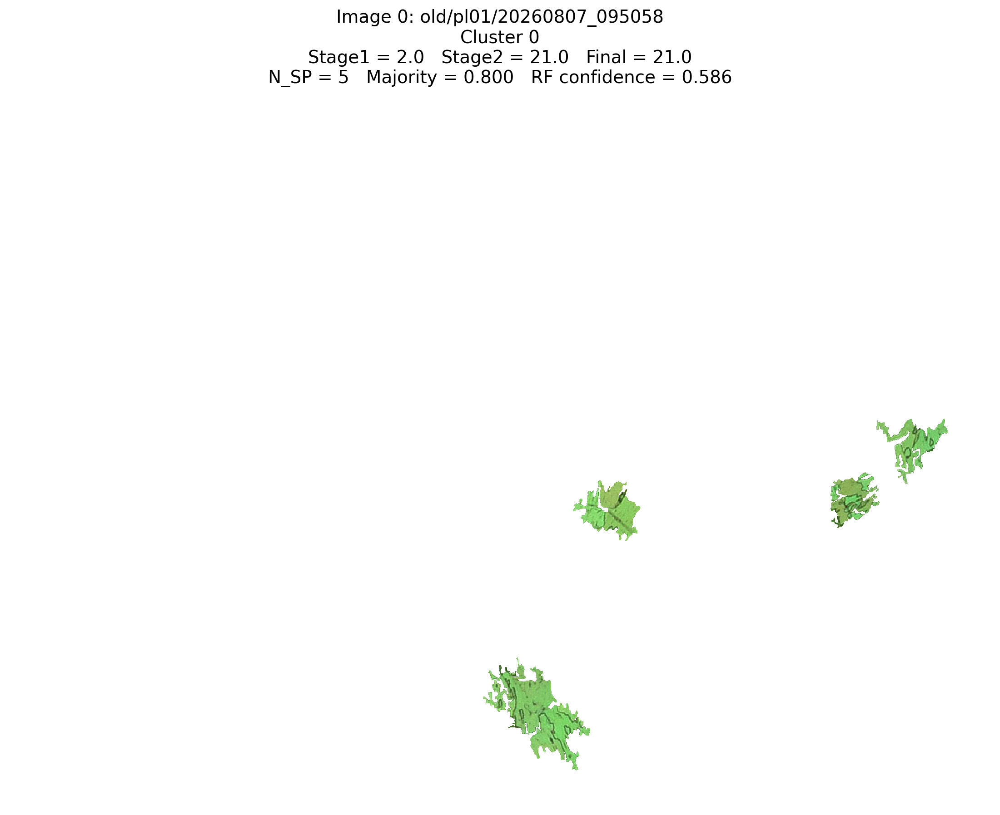

  Cluster 0: N_SP=5


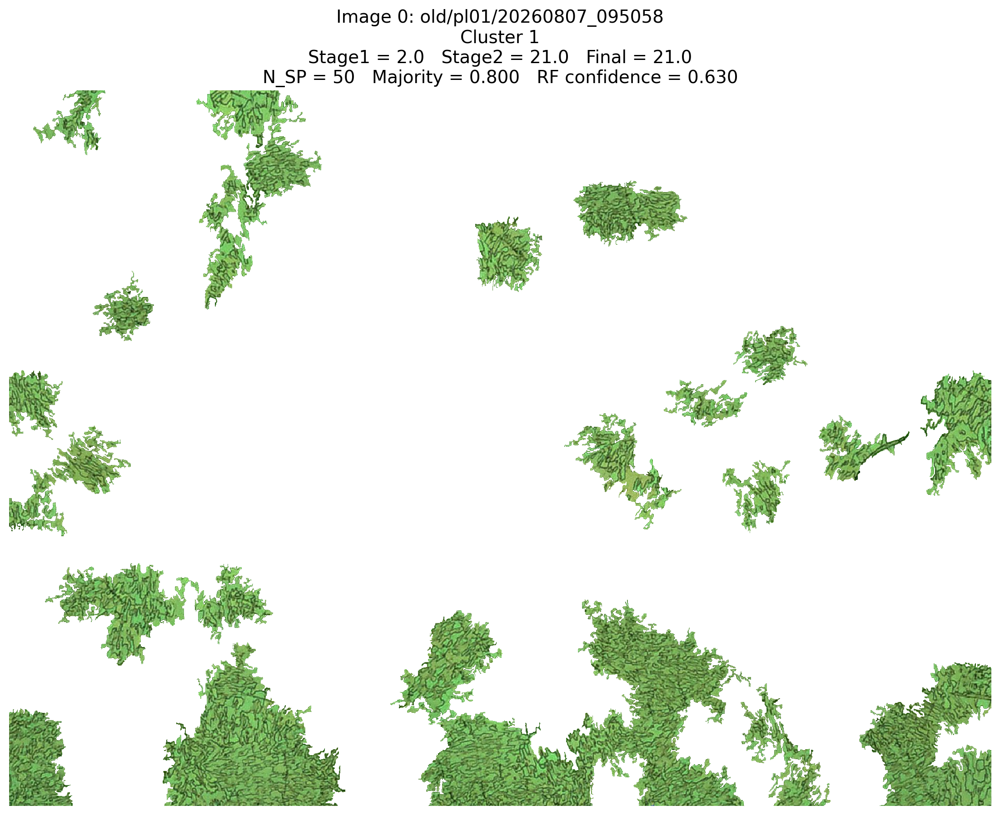

  Cluster 1: N_SP=50


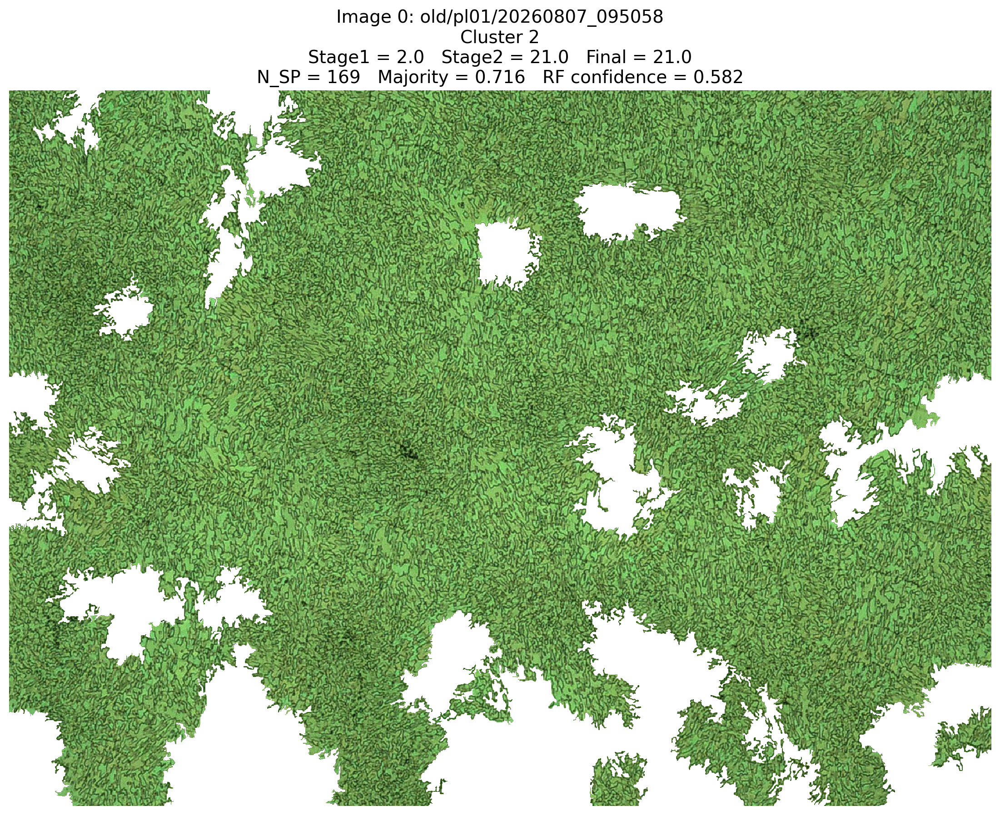

  Cluster 2: N_SP=169

Image 1: old/pl01/20260807_095154
  Number of clusters: 3
  Total SP: 252
  GMM SP: 252


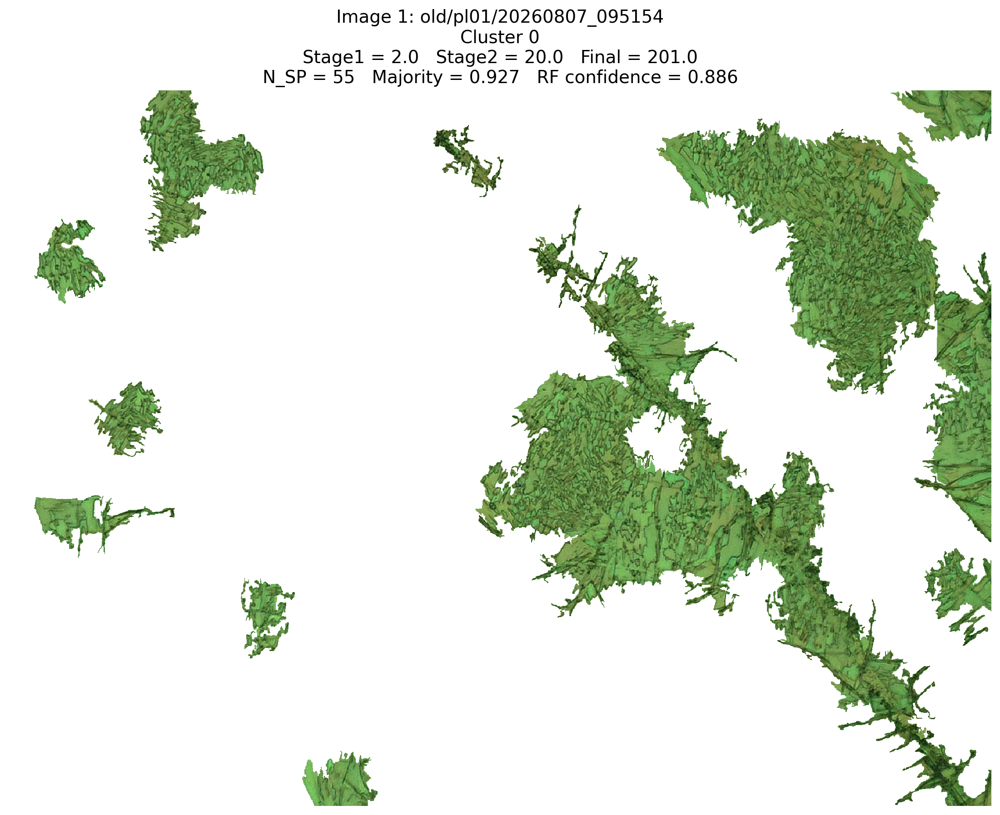

  Cluster 0: N_SP=55


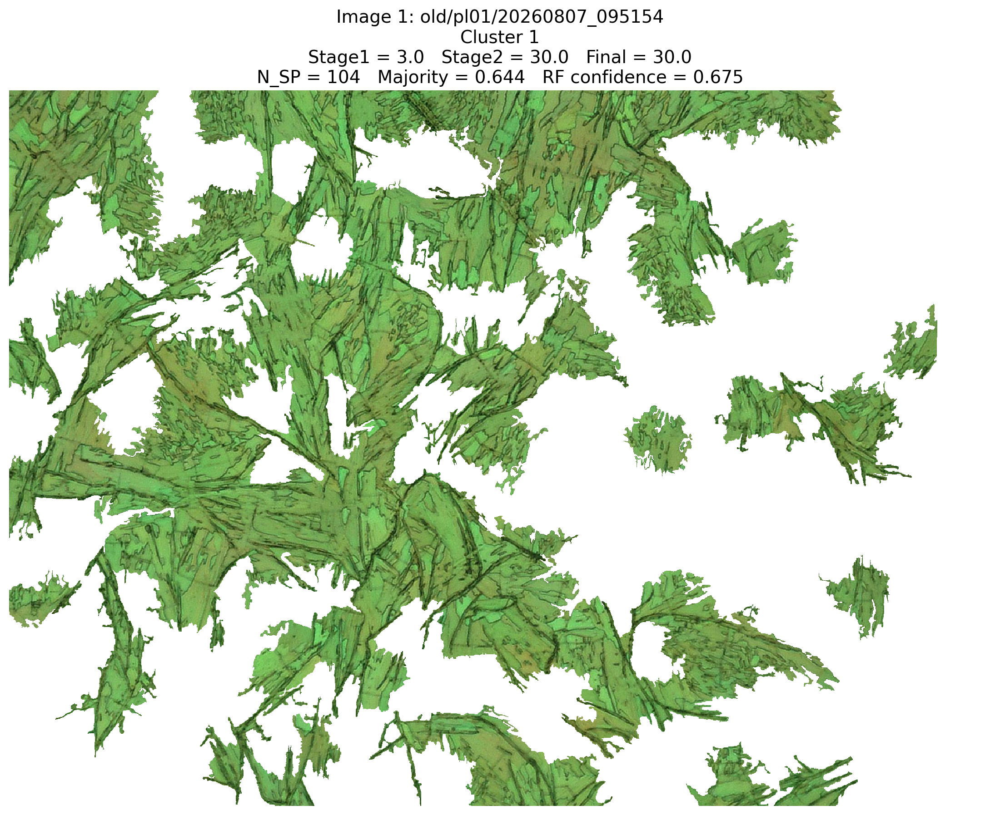

  Cluster 1: N_SP=104


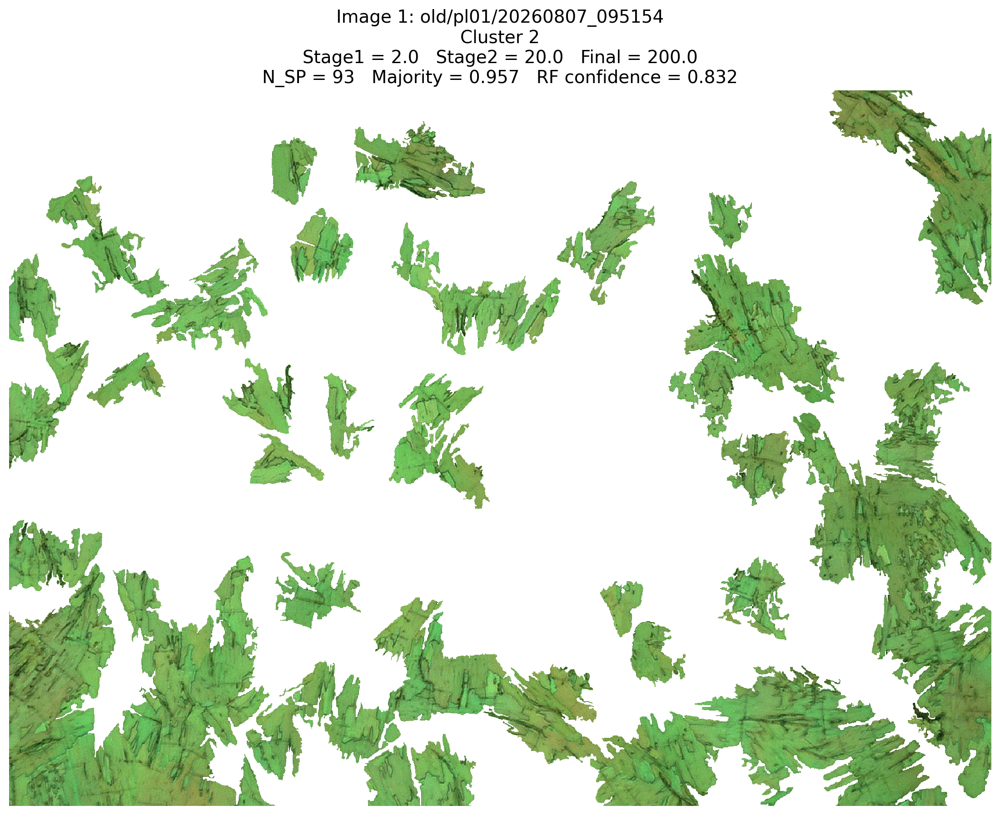

  Cluster 2: N_SP=93

Image 2: old/pl01/20260807_095234
  Number of clusters: 3
  Total SP: 211
  GMM SP: 211


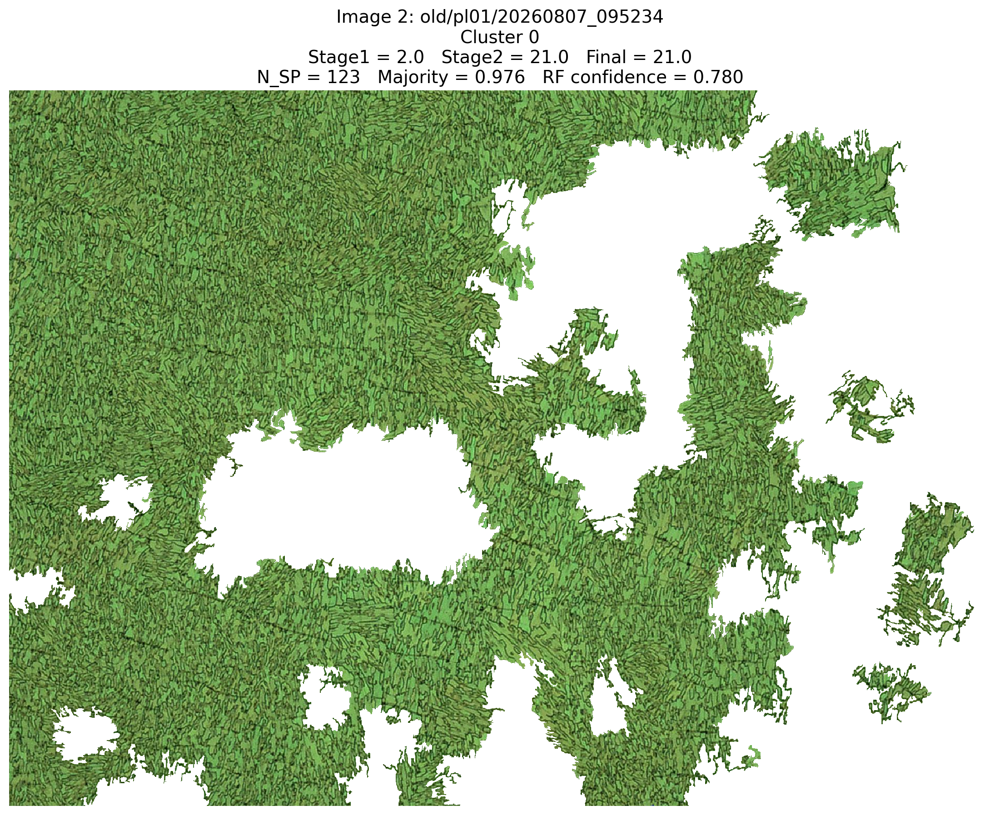

  Cluster 0: N_SP=123


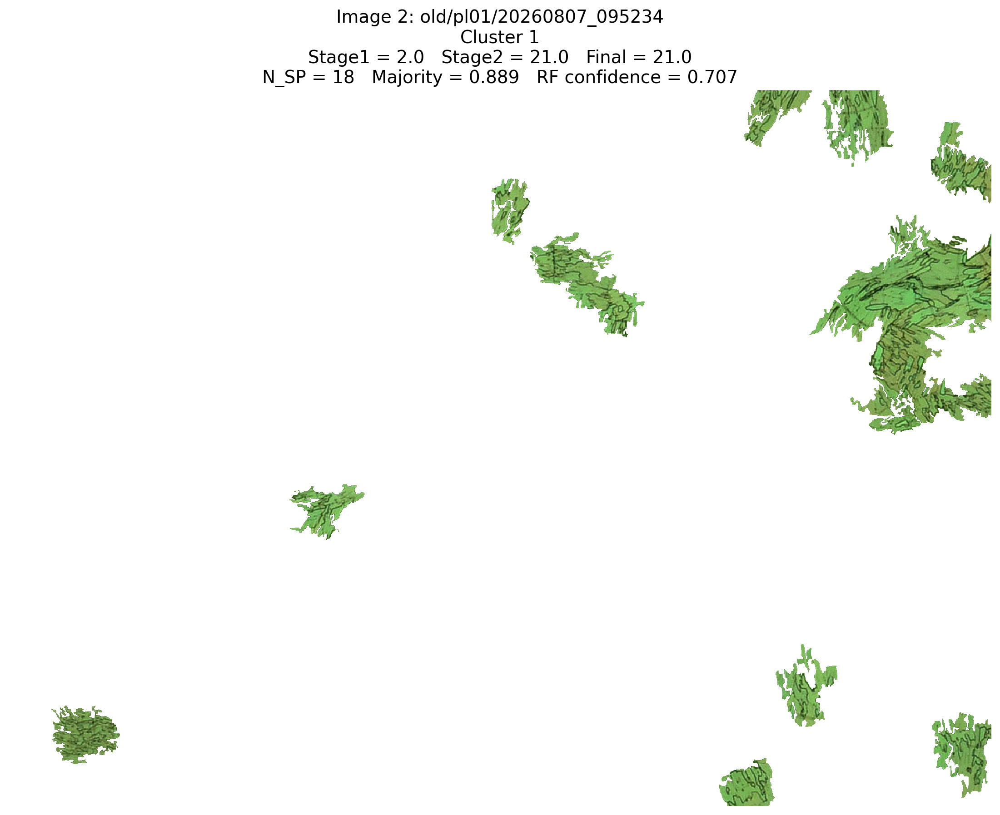

  Cluster 1: N_SP=18


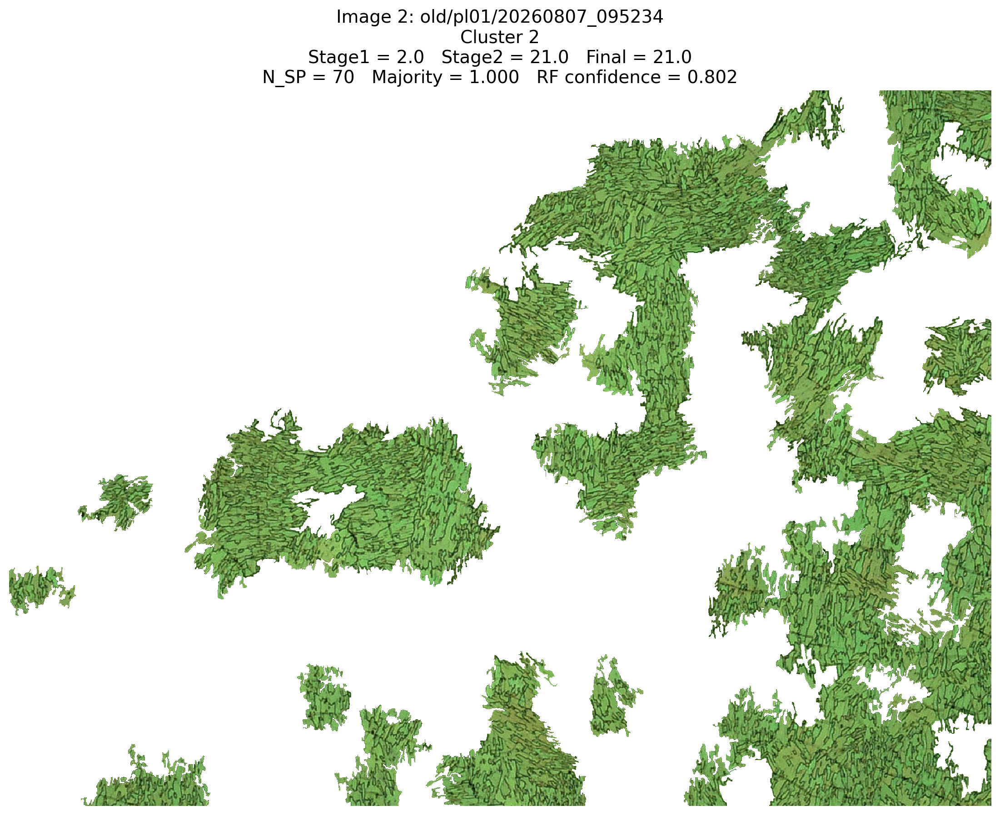

  Cluster 2: N_SP=70


In [56]:
# picture for manual correction 
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

gmm_dir = os.path.join(result_dir, "GMM_results")
segment_dir = os.path.join(path_for_data, "segments")
feature_dir = os.path.join(path_for_data, "RF_features")
cluster_csv = os.path.join(result_dir, "RF_multistage_cluster_results.csv")
cluster_df = pd.read_csv(cluster_csv)

# config
TARGET_GROUP = "old"
TARGET_PLATE = "pl01"

target_image_ids = [i for i, item in enumerate(image_paths) if item["group"] == TARGET_GROUP and item["plate"] == TARGET_PLATE]

print(f"Viewing: {TARGET_GROUP}/{TARGET_PLATE}")
print(f"Number of images: {len(target_image_ids)}")
print(f"Image IDs: {target_image_ids}")

# plot per plate
for image_id in target_image_ids:
    item = image_paths[image_id]

    image = np.load(os.path.join(image_save_dir, f"image_{image_id:04d}.npy"))
    segments = np.load(os.path.join(segment_dir, f"segments_{image_id:04d}.npy"))
    labels = np.load(os.path.join(feature_dir, f"labels_{image_id:03d}.npy"))

    gmm_path = os.path.join(gmm_dir, f"gmm_{image_id:03d}.npz")
    if not os.path.exists(gmm_path):
        print(f"Image {image_id}: GMM result not found")
        continue

    gmm_data = np.load(gmm_path)
    valid_indices = gmm_data["valid_indices"]
    gmm_labels = gmm_data["cluster_labels"]
    gmm_confidence = gmm_data["max_probability"]
    n_components = int(gmm_data["n_components"])
    gmm_data.close()

    print(f"\nImage {image_id}: {item['group']}/{item['plate']}/{item['name']}")
    print(f"  Number of clusters: {n_components}")
    print(f"  Total SP: {len(labels)}")
    print(f"  GMM SP: {len(valid_indices)}")

    # Clusterごと
    for cluster_id in range(n_components):
        cluster_mask = gmm_labels == cluster_id
        sp_indices = valid_indices[cluster_mask]

        cluster_image = np.ones_like(image) * 255

        for sp_index in sp_indices:
            sp_label = labels[sp_index]
            mask = segments == sp_label
            cluster_image[mask] = image[mask]

        info = cluster_df[(cluster_df["image_id"] == image_id) & (cluster_df["cluster_id"] == cluster_id)]

        if len(info) > 0:
            r = info.iloc[0]
            title = (
                f"Image {image_id}: {item['group']}/{item['plate']}/{item['name']}\n"
                f"Cluster {cluster_id}\n"
                f"Stage1 = {r['stage1_label']}   Stage2 = {r['stage2_label']}   Final = {r['final_label']}\n"
                f"N_SP = {len(sp_indices)}   Majority = {r['final_majority']:.3f}   RF confidence = {r['final_rf_confidence']:.3f}"
            )
        else:
            title = (
                f"Image {image_id}: {item['group']}/{item['plate']}/{item['name']}\n"
                f"Cluster {cluster_id}\n"
                f"N_SP = {len(sp_indices)}"
            )

        fig, ax = plt.subplots(figsize=(12, 9), dpi=200)
        ax.imshow(cluster_image, interpolation="nearest")
        ax.set_title(title, fontsize=14)
        ax.axis("off")
        plt.tight_layout()
        plt.show()

        print(f"  Cluster {cluster_id}: N_SP={len(sp_indices)}")

    del image, segments, labels

In [26]:
# implement correction
import os, shutil, numpy as np, pandas as pd

# config
original_dir = result_dir
corrected_dir = os.path.join(path_for_data, "RF_results_corrected")
gmm_dir = os.path.join(original_dir, "GMM_results")
segment_dir = os.path.join(path_for_data, "segments")
cluster_txt_path = os.path.join(original_dir, "cluster_corrections.csv")
os.makedirs(corrected_dir, exist_ok=True)

input_csv = os.path.join(original_dir, "RF_multistage_cluster_area_ratio.csv")
cluster_csv = os.path.join(original_dir, "RF_multistage_cluster_results.csv")
output_csv = os.path.join(corrected_dir, "RF_multistage_cluster_area_ratio.csv")
output_cluster_csv = os.path.join(corrected_dir, "RF_multistage_cluster_results.csv")
correction_csv = os.path.join(corrected_dir, "RF_manual_corrections.csv")


# load csv1
corrections = []
if os.path.exists(cluster_txt_path):
    with open(cluster_txt_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.split()
            if len(parts) < 8:  # don't modify the row without new_class
                continue

            image_id = int(parts[0])
            cluster_id = int(parts[1])
            new_class = parts[7]
            corrections.append((image_id, cluster_id, new_class))
else:
    print(f"WARNING: correction file not found: {cluster_txt_path}")

print("\n========================================")
print("Manual corrections")
print("========================================")
print(f"File: {cluster_txt_path}")
print(f"Number of corrections: {len(corrections)}")

for image_id, cluster_id, new_class in corrections:
    print(f"  Image {image_id}, Cluster {cluster_id} -> {new_class}")



# load csv2
df = pd.read_csv(input_csv)
cluster_df = pd.read_csv(cluster_csv)
cluster_df["final_label"] = cluster_df["final_label"].astype(str)
for filename in os.listdir(original_dir):
    if filename.endswith(".npy"):
        shutil.copy2(os.path.join(original_dir, filename), os.path.join(corrected_dir, filename))


# implement manual correction
history = []
for image_id, cluster_id, new_class in corrections:
    info = cluster_df[(cluster_df["image_id"] == image_id) & (cluster_df["cluster_id"] == cluster_id)]
    if len(info) == 0:
        print(f"WARNING: Image {image_id}, Cluster {cluster_id} not found")
        continue

    old_class = str(info.iloc[0]["final_label"])
    new_class = str(new_class)
    gmm_path = os.path.join(gmm_dir, f"gmm_{image_id:03d}.npz")
    if not os.path.exists(gmm_path):
        print(f"WARNING: GMM file not found: {gmm_path}")
        continue

    gmm = np.load(gmm_path)
    sp_indices = gmm["valid_indices"][gmm["cluster_labels"] == cluster_id]
    gmm.close()

    label_path = os.path.join(corrected_dir, f"final_cluster_labels_{image_id:04d}.npy")
    labels = np.load(label_path)
    labels[sp_indices] = new_class
    np.save(label_path, labels)
    history.append({"image_id": image_id, "cluster_id": cluster_id, "old_class": old_class, "new_class": new_class, "N_superpixels": len(sp_indices)})
    print(f"Image {image_id}, Cluster {cluster_id}: {old_class} -> {new_class}")


# make new csv
corrected_cluster_df = cluster_df.copy()
for row in history:
    mask = (corrected_cluster_df["image_id"] == row["image_id"]) & (corrected_cluster_df["cluster_id"] == row["cluster_id"])
    corrected_cluster_df.loc[mask, "final_label"] = row["new_class"]
    corrected_cluster_df.loc[mask, "final_majority"] = 1.0
corrected_cluster_df.to_csv(output_cluster_csv, index=False)


# make new area ratio csv
drop_cols = [c for c in df.columns if c.startswith("class_") and (c.endswith("_area_ratio") or c.endswith("_area_pixels") or c.endswith("_N"))]
corrected_df = df.drop(columns=drop_cols)

for image_id in corrected_df["image_id"].unique():
    image_id = int(image_id)
    label_path = os.path.join(corrected_dir, f"final_cluster_labels_{image_id:04d}.npy")
    segment_path = os.path.join(segment_dir, f"segments_{image_id:04d}.npy")
    labels = np.load(label_path)
    segments = np.load(segment_path)
    total_pixels = segments.size

    for c in np.unique(labels):
        if c == "":
            continue
        sp_labels = np.where(labels == c)[0]
        pixel_mask = np.isin(segments, sp_labels)
        area_pixels = pixel_mask.sum()
        mask = corrected_df["image_id"] == image_id
        corrected_df.loc[mask, f"class_{c}_area_ratio"] = area_pixels / total_pixels * 100
        corrected_df.loc[mask, f"class_{c}_area_pixels"] = area_pixels
        corrected_df.loc[mask, f"class_{c}_N"] = len(sp_labels)

    del labels, segments



corrected_df.to_csv(output_csv, index=False)
pd.DataFrame(history).to_csv(correction_csv, index=False)
print("\n========================================")
print("Finished correction")
print("========================================")
print(f"Corrected results: {corrected_dir}")
print(f"Area CSV: {output_csv}")
print(f"Cluster CSV: {output_cluster_csv}")
print(f"Correction history: {correction_csv}")


Manual corrections
File: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results/cluster_corrections.csv
Number of corrections: 0

Finished correction
Corrected results: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results_corrected
Area CSV: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results_corrected/RF_multistage_cluster_area_ratio.csv
Cluster CSV: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results_corrected/RF_multistage_cluster_results.csv
Correction history: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results_corrected/RF_manual_corrections.csv


In [ ]:
# additional GMM: check the number of classes
import os, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

def majority_vote(labels):
    if len(labels) == 0: return None, 0.0
    values, counts = np.unique(labels, return_counts=True)
    i = np.argmax(counts)
    return values[i], counts[i] / len(labels)

def run_subclass_gmm(image_paths, path_for_data, target_classes, configs, pca_components=10, representative_n=20, output_name="subclass_GMM"):
    feature_dir = os.path.join(path_for_data, "RF_features")
    segment_dir = os.path.join(path_for_data, "segments")
    gmm_dir = os.path.join(path_for_data, "RF_results", "GMM_results")
    image_dir = os.path.join(path_for_data, "images")
    csv_dir = os.path.join(path_for_data, "RF_results_corrected")
    cluster_csv = os.path.join(csv_dir, "RF_multistage_cluster_results.csv")
    output_dir = os.path.join(csv_dir, "Subclass_GMM")
    os.makedirs(output_dir, exist_ok=True)

    feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]
    cluster_df = pd.read_csv(cluster_csv)

    # --- Load required data once ---
    data = {}
    print("Loading features and GMM results...", flush=True)

    for image_id, item in enumerate(image_paths):
        rows = cluster_df[cluster_df["image_id"] == image_id]
        if len(rows) == 0: continue

        gmm_path = os.path.join(gmm_dir, f"gmm_{image_id:03d}.npz")
        if not os.path.exists(gmm_path): continue

        labels = np.load(os.path.join(feature_dir, f"labels_{image_id:03d}.npy"))
        gmm_data = np.load(gmm_path)
        valid_indices = gmm_data["valid_indices"].copy()
        original_gmm_labels = gmm_data["cluster_labels"].copy()
        gmm_data.close()

        feature_arrays = [np.load(os.path.join(feature_dir, f"features_{f}_{image_id:03d}.npy")) for f in feature_names]
        X = np.column_stack(feature_arrays).astype(np.float64)
        del feature_arrays

        data[image_id] = {
            "item": item,
            "rows": rows.copy(),
            "labels": labels,
            "valid_indices": valid_indices,
            "original_gmm_labels": original_gmm_labels,
            "X": X
        }
        gc.collect()

    print(f"Loaded {len(data)} images.", flush=True)
    all_results = []

    # --- Run each GMM configuration ---
    for cfg in configs:
        cfg_name = cfg["name"]
        n_components_dict = cfg["n_components"]
        print(f"\nRunning {cfg_name}", flush=True)

        pdf_path = os.path.join(output_dir, f"{output_name}_{cfg_name}.pdf")
        pdf = PdfPages(pdf_path)

        for target_class in target_classes:
            if target_class not in n_components_dict: continue
            n_components = n_components_dict[target_class]
            print(f"  Class {target_class}: GMM components = {n_components}", flush=True)

            class_X = []
            class_image_ids = []
            class_original_clusters = []
            class_sp_indices = []

            # --- Collect SPs from all images for the target class ---
            for image_id, d in data.items():
                rows = d["rows"]
                class_rows = rows[rows["final_label"].astype(str).str.startswith(str(target_class))]
                if len(class_rows) == 0: continue

                cluster_ids = class_rows["cluster_id"].astype(int).values
                selected_mask = np.isin(d["original_gmm_labels"], cluster_ids)

                sp_indices = d["valid_indices"][selected_mask]
                original_clusters = d["original_gmm_labels"][selected_mask]

                if len(sp_indices) == 0: continue

                X_tmp = d["X"][sp_indices]
                finite_mask = np.all(np.isfinite(X_tmp), axis=1)

                X_tmp = X_tmp[finite_mask]
                sp_indices = sp_indices[finite_mask]
                original_clusters = original_clusters[finite_mask]

                if len(X_tmp) == 0: continue

                class_X.append(X_tmp)
                class_image_ids.append(np.full(len(X_tmp), image_id, dtype=np.int32))
                class_original_clusters.append(original_clusters)
                class_sp_indices.append(sp_indices)

            if len(class_X) == 0:
                print(f"    No data for Class {target_class}")
                continue

            X_class = np.vstack(class_X)
            image_ids_class = np.concatenate(class_image_ids)
            original_clusters_class = np.concatenate(class_original_clusters)
            sp_indices_class = np.concatenate(class_sp_indices)

            print(f"    Total SP = {len(X_class)}", flush=True)

            if len(X_class) < n_components:
                print("    Skipped: not enough SP")
                del class_X, class_image_ids, class_original_clusters, class_sp_indices
                del X_class, image_ids_class, original_clusters_class, sp_indices_class
                gc.collect()
                continue

            # --- StandardScaler + PCA + GMM ---
            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X_class)

            n_pca = min(pca_components, X_scaled.shape[0], X_scaled.shape[1])
            pca = PCA(n_components=n_pca, random_state=0)
            X_pca = pca.fit_transform(X_scaled)

            gmm = GaussianMixture(
                n_components=n_components,
                covariance_type="full",
                random_state=0,
                n_init=5,
                reg_covar=1e-5
            )

            subclass_labels = gmm.fit_predict(X_pca)
            probabilities = gmm.predict_proba(X_pca)
            confidence = np.max(probabilities, axis=1)

            print(f"    GMM completed. PCA={n_pca}", flush=True)

            # --- Assign subclasses to original GMM clusters by majority vote ---
            cluster_results = []

            for image_id, d in data.items():
                rows = d["rows"]
                class_rows = rows[rows["final_label"].astype(str).str.startswith(str(target_class))]
                if len(class_rows) == 0: continue

                cluster_ids = class_rows["cluster_id"].astype(int).values

                for cluster_id in cluster_ids:
                    mask = (image_ids_class == image_id) & (original_clusters_class == cluster_id)
                    if not np.any(mask): continue

                    sub_labels = subclass_labels[mask]
                    sub_conf = confidence[mask]

                    majority, fraction = majority_vote(sub_labels)

                    cluster_results.append({
                        "config": cfg_name,
                        "image_id": image_id,
                        "group": d["item"]["group"],
                        "plate": d["item"]["plate"],
                        "name": d["item"]["name"],
                        "parent_class": target_class,
                        "cluster_id": cluster_id,
                        "N_superpixels": int(np.sum(mask)),
                        "subclass": int(majority),
                        "subclass_majority": float(fraction),
                        "subclass_mean_confidence": float(np.mean(sub_conf))
                    })

            # --- Select representative clusters for each subclass ---
            cluster_result_df = pd.DataFrame(cluster_results)

            for subclass in range(n_components):
                sub_df = cluster_result_df[cluster_result_df["subclass"] == subclass].copy()
                if len(sub_df) == 0: continue

                sub_df = sub_df.sort_values(
                    ["subclass_majority", "N_superpixels"],
                    ascending=False
                ).head(representative_n)

                print(f"    Subclass {subclass}: {len(sub_df)} representative clusters", flush=True)

                # --- Arrange four images per page ---
                for page_start in range(0, len(sub_df), 4):
                    page_df = sub_df.iloc[page_start:page_start+4]

                    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
                    axes = np.asarray(axes).ravel()

                    for position, (_, row) in enumerate(page_df.iterrows()):
                        image_id = int(row["image_id"])
                        cluster_id = int(row["cluster_id"])
                        d = data[image_id]

                        # Load images and segments only when creating the PDF
                        image = np.load(os.path.join(image_dir, f"image_{image_id:04d}.npy"))
                        segments = np.load(os.path.join(segment_dir, f"segments_{image_id:04d}.npy"))

                        # --- Display only the selected original GMM cluster ---
                        cluster_mask = d["original_gmm_labels"] == cluster_id
                        sp_indices = d["valid_indices"][cluster_mask]
                        sp_labels = d["labels"][sp_indices]

                        mask = np.isin(segments, sp_labels)
                        display = np.full_like(image, 255)
                        display[mask] = image[mask]

                        ax = axes[position]
                        ax.imshow(display, interpolation="nearest")
                        ax.set_title(
                            f"Class {target_class} / Subclass {subclass}\n"
                            f"{row['group']}/{row['plate']}  "
                            f"img={image_id}, cluster={cluster_id}\n"
                            f"N_SP={row['N_superpixels']}  "
                            f"majority={row['subclass_majority']:.3f}",
                            fontsize=11
                        )
                        ax.axis("off")

                        del image, segments, mask, display
                        gc.collect()

                    for j in range(len(page_df), 4):
                        axes[j].axis("off")

                    fig.suptitle(
                        f"{cfg_name} | Class {target_class} | Subclass {subclass} | "
                        f"representatives {page_start+1}-{page_start+len(page_df)}",
                        fontsize=15
                    )
                    fig.tight_layout(rect=[0, 0, 1, 0.95])

                    pdf.savefig(fig, dpi=180)
                    plt.close(fig)
                    del fig, axes, page_df
                    gc.collect()

            all_results.extend(cluster_results)

            del class_X, class_image_ids, class_original_clusters, class_sp_indices
            del X_class, image_ids_class, original_clusters_class, sp_indices_class
            del scaler, X_scaled, pca, X_pca, gmm, subclass_labels, probabilities, confidence
            del cluster_results, cluster_result_df
            gc.collect()

        pdf.close()
        print(f"  PDF: {pdf_path}", flush=True)

    # --- Save CSV results ---
    result_df = pd.DataFrame(all_results)
    csv_path = os.path.join(output_dir, f"{output_name}_cluster_results.csv")
    result_df.to_csv(csv_path, index=False)

    for image_id in list(data.keys()):
        del data[image_id]
    del data
    gc.collect()

    print("\nFinished.")
    print(f"CSV: {csv_path}")
    for cfg in configs:
        cfg_name = cfg["name"]
        print(f"PDF [{cfg_name}]: {os.path.join(output_dir, f'{output_name}_{cfg_name}.pdf')}")

    return result_df

In [ ]:
# additional GMM: check the number of classes
# configs = [
#     {"name": "class11_GMM2", "n_components": {11: 2}},
#     {"name": "class12_GMM2", "n_components": {12: 2}},
#     {"name": "class21_GMM2", "n_components": {21: 2}},
#     {"name": "class21_GMM3", "n_components": {21: 3}},
#     {"name": "class30_GMM2", "n_components": {30: 2}},
#     {"name": "class30_GMM3", "n_components": {30: 3}},
#     {"name": "class30_GMM4", "n_components": {30: 4}},
# ]

configs = [
    {"name": "class200_GMM2", "n_components": {200: 2}},
    {"name": "class200_GMM3", "n_components": {200: 3}},
    # {"name": "class11_GMM3", "n_components": {11: 3}},
    # {"name": "class11_GMM4", "n_components": {11: 4}},
    # {"name": "class21_GMM4", "n_components": {21: 4}},
    # {"name": "class30_GMM4", "n_components": {30: 4}},
    # {"name": "class30_GMM5", "n_components": {30: 5}},
]

target_classes = [200]

subclass_df = run_subclass_gmm(
    image_paths,
    path_for_data,
    target_classes,
    configs,
    pca_components=10,
    representative_n=20
)

Loading features and GMM results...


Loaded 24 images.

Running class200_GMM2
  Class 200: GMM components = 2
    Total SP = 356
    GMM completed. PCA=10
    Subclass 0: 1 representative clusters
    Subclass 1: 4 representative clusters
  PDF: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results_corrected/Subclass_GMM/subclass_GMM_class200_GMM2.pdf

Running class200_GMM3
  Class 200: GMM components = 3
    Total SP = 356
    GMM completed. PCA=10
    Subclass 0: 3 representative clusters
    Subclass 1: 1 representative clusters
    Subclass 2: 1 representative clusters
  PDF: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results_corrected/Subclass_GMM/subclass_GMM_class200_GMM3.pdf

Finished.
CSV: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results_corrected/Subclass_GMM/subclass_GMM_cluster_results.csv
PDF [class200_GMM2]: /home/kmanabe2403/document/dune/superpixel/data_sample/pipeline_output_sample/RF_results_c

In [ ]:
# additional GMM: implement GMM & make csv
import os, gc
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

def majority_vote(labels):
    if len(labels) == 0: return None, 0.0
    values, counts = np.unique(labels, return_counts=True)
    i = np.argmax(counts)
    return values[i], counts[i] / len(labels)

def run_subclass_gmm(image_paths, path_for_data, configs, pca_components=10):
    feature_dir = os.path.join(path_for_data, "RF_features")
    segment_dir = os.path.join(path_for_data, "segments")
    gmm_dir = os.path.join(result_dir, "GMM_results")
    csv_dir = csv_dir = os.path.join(path_for_data, "RF_results_corrected")
    cluster_csv = os.path.join(csv_dir, "RF_multistage_cluster_results.csv")
    output_dir = os.path.join(csv_dir, "Subclass_GMM")
    os.makedirs(output_dir, exist_ok=True)

    feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]
    cluster_df = pd.read_csv(cluster_csv)
    cluster_df["final_label"] = cluster_df["final_label"].astype(str)

    loaded = {}

    for image_id, item in enumerate(image_paths):
        print(f"Loading {image_id+1}/{len(image_paths)}: {item['group']}/{item['plate']}/{item['name']}", flush=True)
        rows = cluster_df[cluster_df["image_id"] == image_id].copy()
        if len(rows) == 0: continue

        gmm_path = os.path.join(gmm_dir, f"gmm_{image_id:03d}.npz")
        if not os.path.exists(gmm_path): continue

        labels = np.load(os.path.join(feature_dir, f"labels_{image_id:03d}.npy"))
        gmm_data = np.load(gmm_path)
        valid_indices = gmm_data["valid_indices"]
        original_gmm_labels = gmm_data["cluster_labels"]
        gmm_data.close()

        feature_arrays = [np.load(os.path.join(feature_dir, f"features_{f}_{image_id:03d}.npy")) for f in feature_names]
        X = np.column_stack(feature_arrays).astype(np.float64)
        del feature_arrays

        finite_mask = np.all(np.isfinite(X[valid_indices]), axis=1)
        loaded[image_id] = {"item":item,"rows":rows,"labels":labels,"valid_indices":valid_indices,"original_gmm_labels":original_gmm_labels,"X":X,"finite_mask":finite_mask}

    print(f"\nLoaded {len(loaded)} images.")

    for cfg in configs:
        cfg_name = cfg["name"]
        n_components_dict = {str(k): int(v) for k, v in cfg["n_components"].items()}
        print(f"\nRunning {cfg_name}")

        cluster_subclass = {}
        subclass_results = []

        # --- Run GMM for each specified parent class ---
        for parent_class, n_components in n_components_dict.items():
            all_X, all_image_ids, all_original_clusters, all_sp_indices = [], [], [], []

            for image_id, d in loaded.items():
                class_rows = d["rows"][d["rows"]["final_label"] == parent_class]
                if len(class_rows) == 0: continue

                cluster_ids = class_rows["cluster_id"].astype(int).values
                mask = np.isin(d["original_gmm_labels"], cluster_ids)
                sp_indices = d["valid_indices"][mask]
                original_clusters = d["original_gmm_labels"][mask]
                finite = d["finite_mask"][mask]

                sp_indices = sp_indices[finite]
                original_clusters = original_clusters[finite]
                if len(sp_indices) == 0: continue

                all_X.append(d["X"][sp_indices])
                all_image_ids.extend([image_id] * len(sp_indices))
                all_original_clusters.extend(original_clusters)
                all_sp_indices.extend(sp_indices)

            if len(all_X) == 0:
                print(f"  Class {parent_class}: no SP")
                continue

            X_class = np.vstack(all_X)
            all_image_ids = np.asarray(all_image_ids)
            all_original_clusters = np.asarray(all_original_clusters)
            all_sp_indices = np.asarray(all_sp_indices)

            print(f"  Class {parent_class}: N_SP={len(X_class)}, components={n_components}")

            if len(X_class) < n_components:
                print("    skipped: not enough SP")
                del X_class, all_X, all_image_ids, all_original_clusters, all_sp_indices
                gc.collect()
                continue

            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X_class)
            n_pca = min(pca_components, X_scaled.shape[0], X_scaled.shape[1])
            pca = PCA(n_components=n_pca, random_state=0)
            X_pca = pca.fit_transform(X_scaled)

            gmm = GaussianMixture(n_components=n_components, covariance_type="full", random_state=0, n_init=5, reg_covar=1e-5)
            subclass_labels = gmm.fit_predict(X_pca)
            probabilities = gmm.predict_proba(X_pca)
            confidence = np.max(probabilities, axis=1)

            # --- Assign subclasses to original GMM clusters by majority vote ---
            for image_id in np.unique(all_image_ids):
                d = loaded[image_id]
                class_rows = d["rows"][d["rows"]["final_label"] == parent_class]
                cluster_ids = class_rows["cluster_id"].astype(int).values

                for cluster_id in cluster_ids:
                    mask = (all_image_ids == image_id) & (all_original_clusters == cluster_id)
                    if not np.any(mask): continue

                    majority, fraction = majority_vote(subclass_labels[mask])
                    subclass = int(majority)
                    new_label = f"{parent_class}_{subclass}"

                    cluster_subclass[(image_id, cluster_id)] = {
                        "parent_class": parent_class,
                        "subclass": subclass,
                        "new_label": new_label,
                        "majority": fraction,
                        "confidence": float(np.mean(confidence[mask])),
                        "N": int(np.sum(mask))
                    }

                    subclass_results.append({
                        "image_id": image_id,
                        "group": d["item"]["group"],
                        "plate": d["item"]["plate"],
                        "name": d["item"]["name"],
                        "cluster_id": cluster_id,
                        "parent_class": parent_class,
                        "subclass": subclass,
                        "new_label": new_label,
                        "N_superpixels": int(np.sum(mask)),
                        "subclass_majority": fraction,
                        "subclass_gmm_confidence": float(np.mean(confidence[mask])
                    )})

            del X_class, X_scaled, X_pca, scaler, pca, gmm, subclass_labels, probabilities, confidence
            del all_X, all_image_ids, all_original_clusters, all_sp_indices
            gc.collect()

        # --- Create SP labels ---
        # First assign the original RF label to all SPs, then overwrite GMM target classes
        for image_id, d in loaded.items():
            labels = d["labels"]
            new_labels = np.full(len(labels), "", dtype="<U30")

            for _, row in d["rows"].iterrows():
                cluster_id = int(row["cluster_id"])
                original_label = str(row["final_label"])
                mask = d["original_gmm_labels"] == cluster_id
                sp_indices = d["valid_indices"][mask]
                new_labels[sp_indices] = original_label

            for (img, cluster_id), info in cluster_subclass.items():
                if img != image_id: continue
                mask = d["original_gmm_labels"] == cluster_id
                sp_indices = d["valid_indices"][mask]
                new_labels[sp_indices] = info["new_label"]

            np.save(os.path.join(output_dir, f"subclass_labels_{cfg_name}_{image_id:04d}.npy"), new_labels)

        # --- Save cluster CSV ---
        # Keep all original RF clusters
        all_cluster_results = []

        for image_id, d in loaded.items():
            for _, row in d["rows"].iterrows():
                cluster_id = int(row["cluster_id"])
                original_label = str(row["final_label"])

                if (image_id, cluster_id) in cluster_subclass:
                    info = cluster_subclass[(image_id, cluster_id)]
                    all_cluster_results.append({
                        "image_id": image_id,
                        "group": d["item"]["group"],
                        "plate": d["item"]["plate"],
                        "name": d["item"]["name"],
                        "cluster_id": cluster_id,
                        "parent_class": original_label,
                        "subclass": info["subclass"],
                        "new_label": info["new_label"],
                        "N_superpixels": info["N"],
                        "subclass_majority": info["majority"],
                        "subclass_gmm_confidence": info["confidence"]
                    })
                else:
                    all_cluster_results.append({
                        "image_id": image_id,
                        "group": d["item"]["group"],
                        "plate": d["item"]["plate"],
                        "name": d["item"]["name"],
                        "cluster_id": cluster_id,
                        "parent_class": original_label,
                        "subclass": np.nan,
                        "new_label": original_label,
                        "N_superpixels": int(row["N_superpixels"]),
                        "subclass_majority": np.nan,
                        "subclass_gmm_confidence": np.nan
                    })

        subclass_cluster_df = pd.DataFrame(all_cluster_results)
        subclass_cluster_csv = os.path.join(output_dir, f"Subclass_GMM_{cfg_name}_cluster_results.csv")
        subclass_cluster_df.to_csv(subclass_cluster_csv, index=False)

        # --- Save area ratio CSV ---
        new_area_rows = []

        for image_id, d in loaded.items():
            item = d["item"]
            labels = d["labels"]
            segments = np.load(os.path.join(segment_dir, f"segments_{image_id:04d}.npy"))
            new_labels = np.load(os.path.join(output_dir, f"subclass_labels_{cfg_name}_{image_id:04d}.npy"))
            total_pixels = segments.size

            result = {"image_id":image_id,"group":item["group"],"plate":item["plate"],"name":item["name"],"image_path":item["path"]}

            for new_label in np.unique(new_labels):
                if new_label == "": continue

                sp_indices = np.where(new_labels == new_label)[0]
                sp_labels = labels[sp_indices]
                pixel_mask = np.isin(segments, sp_labels)
                area_pixels = int(np.sum(pixel_mask))

                result[f"class_{new_label}_area_ratio"] = area_pixels / total_pixels * 100
                result[f"class_{new_label}_area_pixels"] = area_pixels
                result[f"class_{new_label}_N"] = len(sp_indices)

            new_area_rows.append(result)
            del segments, new_labels
            gc.collect()

        new_area_df = pd.DataFrame(new_area_rows)
        new_area_csv = os.path.join(output_dir, f"Subclass_GMM_{cfg_name}_area_ratio.csv")
        new_area_df.to_csv(new_area_csv, index=False)

        print(f"\n{cfg_name} finished.")
        print(f"  Cluster CSV: {subclass_cluster_csv}")
        print(f"  Area CSV:    {new_area_csv}")

        del cluster_subclass, subclass_results, all_cluster_results, subclass_cluster_df, new_area_rows, new_area_df
        gc.collect()

    for image_id in list(loaded.keys()):
        del loaded[image_id]
    del loaded
    gc.collect()

    print("\nFinished all subclass GMM configurations.")

In [35]:
# additional GMM: implement GMM & make csv
import os
import pandas as pd

# 追加GMM config
configs = [
    {"name": "GMM", "n_components": {"0":4, "200":2, "21":4, "30":4}},
]

subclass_results = run_subclass_gmm(
    image_paths=image_paths,
    path_for_data=path_for_data,
    configs=configs,
    pca_components=10
)

output_dir = os.path.join(path_for_data, "RF_results_corrected", "Subclass_GMM")

csv_path = os.path.join(output_dir, "Subclass_GMM_GMM_cluster_results.csv")

df = pd.read_csv(csv_path)

labels = sorted(df["new_label"].dropna().astype(str).unique())

print(f"Number of labels: {len(labels)}")
print(labels)

Loading 1/24: old/pl01/20260807_095058
Loading 2/24: old/pl01/20260807_095154
Loading 3/24: old/pl01/20260807_095234
Loading 4/24: old/pl01/20260807_095334
Loading 5/24: old/pl02/20260807_100728
Loading 6/24: old/pl02/20260807_100809
Loading 7/24: old/pl02/20260807_100913
Loading 8/24: old/pl02/20260807_100946
Loading 9/24: old/pl04/20260806_135656
Loading 10/24: old/pl04/20260806_135735
Loading 11/24: old/pl04/20260806_135900
Loading 12/24: old/pl04/20260806_135944
Loading 13/24: new/pl01/20260806_130825
Loading 14/24: new/pl01/20260806_130921
Loading 15/24: new/pl01/20260806_131007
Loading 16/24: new/pl01/20260806_131047
Loading 17/24: new/pl02/20260806_131657
Loading 18/24: new/pl02/20260806_131743
Loading 19/24: new/pl02/20260806_131837
Loading 20/24: new/pl02/20260806_131909
Loading 21/24: new/pl04/20260806_132552
Loading 22/24: new/pl04/20260806_132631
Loading 23/24: new/pl04/20260806_132708
Loading 24/24: new/pl04/20260806_132744

Loaded 24 images.

Running GMM
  Class 0: N_SP=6

In [ ]:
#


7-image mean: 95% CI
group plate  n_images  n_use    mean_7    std_7  95CI_low  95CI_high  95CI_half
  new  pl01         8      7  0.000000 0.000000  0.000000   0.000000   0.000000
  new  pl02         8      7 21.286349 5.743783 15.974236  26.598462   5.312113
  new  pl04         8      7  0.000000 0.000000  0.000000   0.000000   0.000000
  new  pl05         8      7  0.000000 0.000000  0.000000   0.000000   0.000000
  new  pl06         8      7  0.000000 0.000000  0.000000   0.000000   0.000000
  new  pl07         8      7  0.000000 0.000000  0.000000   0.000000   0.000000
  new  pl08         8      7  0.000000 0.000000  0.000000   0.000000   0.000000
  new  pl09         8      7  0.000000 0.000000  0.000000   0.000000   0.000000
  new  pl10         8      7  0.000000 0.000000  0.000000   0.000000   0.000000
  new  pl11         8      7  0.000000 0.000000  0.000000   0.000000   0.000000
  new  pl12         8      7  0.000000 0.000000  0.000000   0.000000   0.000000
  new  pl13       

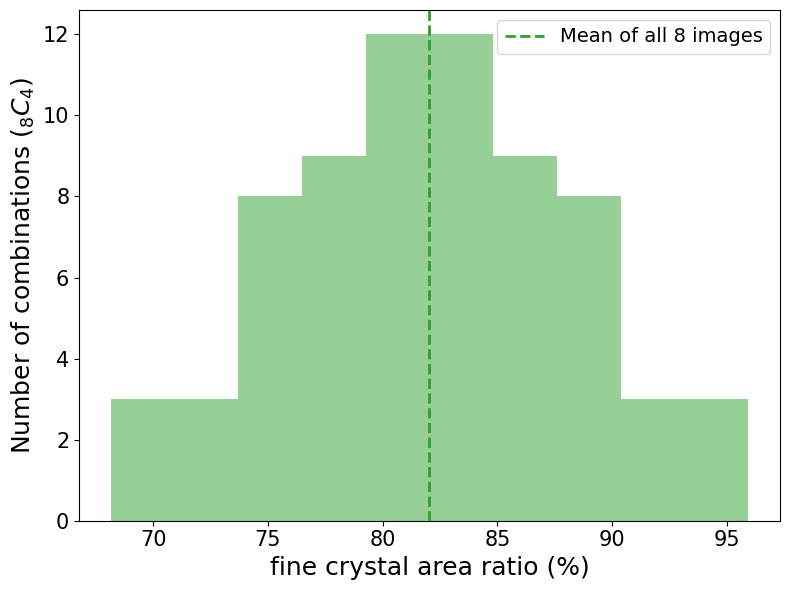

In [ ]:
# sampling systematic error: histogram
import os, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

target_classes = ["0_0", "0_1", "0_2", "0_3"]
rf_csv = "/home/kmanabe2403/document/dune/superpixel/data/pipeline_output/RF_results4_corrected/Subclass_GMM/Subclass_GMM_GMM_area_ratio.csv"

df = pd.read_csv(rf_csv)
df["group"] = [item["group"] for item in image_paths]
df["plate"] = [item["plate"] for item in image_paths]

area_cols = [f"class_{c}_area_ratio" for c in target_classes]
df["target_area_ratio"] = df[area_cols].fillna(0).sum(axis=1)

results = []
for (group, plate), plate_df in df.groupby(["group", "plate"]):
    values = plate_df["target_area_ratio"].dropna().values
    n = len(values)
    if n < 2: continue

    leave_one_out_means = np.array([np.mean(np.delete(values, i)) for i in range(n)])
    n_use = n - 1
    mean_7 = np.mean(leave_one_out_means)
    std_7 = np.std(leave_one_out_means, ddof=1)
    sem_7 = std_7 / np.sqrt(n_use)
    t_value = t.ppf(0.975, df=n_use - 1)
    ci_half = t_value * sem_7

    results.append({
        "group": group, "plate": plate, "n_images": n, "n_use": n_use,
        "mean_7": mean_7, "std_7": std_7,
        "95CI_low": mean_7 - ci_half, "95CI_high": mean_7 + ci_half,
        "95CI_half": ci_half
    })

result_df = pd.DataFrame(results)

print("\n7-image mean: 95% CI")
print(result_df.to_string(index=False))

# --- Histogram of means from all 8C4 combinations ---
class_groups = {
    "fine crystal": ["0_0", "0_1", "0_2", "0_3"],
    "elongated crystal": ["10", "11", "12"],
    "plate-like crystal": ["200_0", "200_1", "201", "21_0", "21_1", "21_2", "21_3"],
    "empty": ["30_0", "30_1", "30_2", "30_3", "31", "32"],
}

TARGET_CLASS = "fine crystal"
TARGET_GROUP = "new"
TARGET_PLATE = "pl17"
N_TOTAL = 8
N_USE = 4

data = df[(df["group"] == TARGET_GROUP) & (df["plate"] == TARGET_PLATE)].copy()
source_classes = class_groups[TARGET_CLASS]
area_cols = [f"class_{c}_area_ratio" for c in source_classes]
values = data[area_cols].fillna(0).sum(axis=1).dropna().values

print(f"\n{TARGET_CLASS}, {TARGET_GROUP}, {TARGET_PLATE}")
print(f"Number of images: {len(values)}")

if len(values) != N_TOTAL:
    print(f"Warning: Expected {N_TOTAL} images, found {len(values)}.")
else:
    combinations = list(itertools.combinations(range(N_TOTAL), N_USE))
    combination_means = np.array([np.mean(values[list(idx)]) for idx in combinations])

    print(f"Number of combinations: {len(combination_means)}")
    print(f"Mean of all 8 images: {np.mean(values):.2f}")
    print(f"Minimum: {np.min(combination_means):.2f}")
    print(f"Maximum: {np.max(combination_means):.2f}")
    print(f"Half range: {(np.max(combination_means) - np.min(combination_means)) / 2:.2f}")

    plt.figure(figsize=(8, 6))
    plt.hist(combination_means, bins=10, alpha=0.5, color="C2")
    plt.axvline(np.mean(values), linestyle="--", linewidth=2, label="Mean of all 8 images", color="C2")
    plt.xlabel(f"{TARGET_CLASS} area ratio (%)", fontsize=18)
    plt.ylabel("Number of combinations ($_8C_4$)", fontsize=18)
    plt.xticks(fontsize=15)
    plt.yticks(fontsize=15)
    plt.legend(fontsize=14)
    plt.tight_layout()
    plt.show()


=== Required number of images ===
group plate  n_images      mean       min        max  stability  required_images
  new  pl01         8  0.000000  0.000000   0.000000   0.000000              NaN
  new  pl02         8 21.286349 10.041541  24.327256   7.142857              NaN
  new  pl04         8  0.000000  0.000000   0.000000   0.000000              NaN
  new  pl05         8  0.000000  0.000000   0.000000   0.000000              NaN
  new  pl06         8  0.000000  0.000000   0.000000   0.000000              NaN
  new  pl07         8  0.000000  0.000000   0.000000   0.000000              NaN
  new  pl08         8  0.000000  0.000000   0.000000   0.000000              NaN
  new  pl09         8  0.000000  0.000000   0.000000   0.000000              NaN
  new  pl10         8  0.000000  0.000000   0.000000   0.000000              NaN
  new  pl11         8  0.000000  0.000000   0.000000   0.000000              NaN
  new  pl12         8  0.000000  0.000000   0.000000   0.000000           

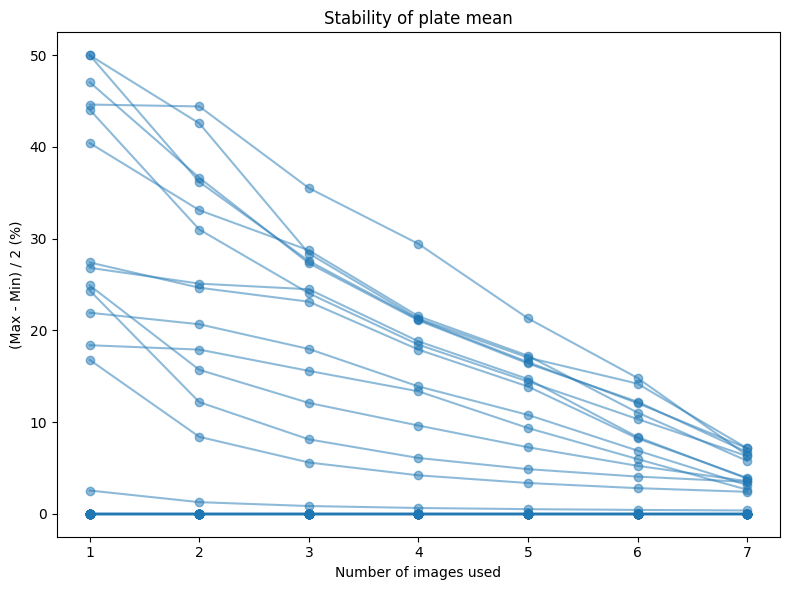


Saved:
/home/kmanabe2403/document/dune/superpixel/data/pipeline_output/plate_mean_stability.csv
/home/kmanabe2403/document/dune/superpixel/data/pipeline_output/plate_required_images.csv


In [ ]:
# sampling systematic error: plot
import os, itertools, numpy as np, pandas as pd
import matplotlib.pyplot as plt

target_classes = ["0_0", "0_1", "0_2", "0_3"]
rf_csv = "/home/kmanabe2403/document/dune/superpixel/data/pipeline_output/RF_results4_corrected/Subclass_GMM/Subclass_GMM_GMM_area_ratio.csv"

df = pd.read_csv(rf_csv)
df["group"] = [item["group"] for item in image_paths]
df["plate"] = [item["plate"] for item in image_paths]

area_cols = [f"class_{c}_area_ratio" for c in target_classes]
for col in area_cols:
    if col not in df.columns: raise ValueError(f"{col} がRF CSVにありません")

df["target_area_ratio"] = df[area_cols].fillna(0).sum(axis=1)

results = []
for (group, plate), plate_df in df.groupby(["group", "plate"]):
    values = plate_df["target_area_ratio"].dropna().values
    n_images = len(values)
    if n_images < 2: continue

    actual_mean = np.mean(values)

    # --- Calculate stability up to the maximum number of images minus one ---
    for n_use in range(1, n_images):
        sample_means = np.array([np.mean(values[list(indices)]) for indices in itertools.combinations(range(n_images), n_use)])
        mean_min = sample_means.min()
        mean_max = sample_means.max()
        stability = (mean_max - mean_min) / 2

        results.append({
            "group": group, "plate": plate, "n_use": n_use, "n_images": n_images,
            "mean": actual_mean, "min": mean_min, "max": mean_max, "stability": stability
        })

stability_df = pd.DataFrame(results)

# --- 1. Determine the required number of images for each plate ---
required_images = []
for (group, plate), data in stability_df.groupby(["group", "plate"]):
    data = data.sort_values("n_use")
    stable = data[data["stability"] <= MAX_ERROR] if "MAX_ERROR" in globals() else data.iloc[0:0]
    required_n = stable["n_use"].iloc[0] if len(stable) > 0 else np.nan
    row = data.iloc[-1]

    required_images.append({
        "group": group, "plate": plate, "n_images": int(row["n_images"]),
        "mean": row["mean"], "min": row["min"], "max": row["max"],
        "stability": row["stability"], "required_images": required_n
    })

required_df = pd.DataFrame(required_images)

print("\n=== Required number of images ===")
print(required_df.to_string(index=False))

# --- 2. Plot the relationship between number of images and stability ---
plt.figure(figsize=(8, 6))
for (group, plate), data in stability_df.groupby(["group", "plate"]):
    plt.plot(data["n_use"], data["stability"], marker="o", color="C0", alpha=0.5)

plt.xlabel("Number of images used")
plt.ylabel("(Max - Min) / 2 (%)")
plt.title("Stability of plate mean")
plt.xticks(range(1, int(stability_df["n_use"].max()) + 1))
# plt.grid()
plt.tight_layout()
plt.show()

# --- 3. Save results ---
stability_csv = os.path.join(path_for_data, "plate_mean_stability.csv")
required_csv = os.path.join(path_for_data, "plate_required_images.csv")

stability_df.to_csv(stability_csv, index=False)
required_df.to_csv(required_csv, index=False)

print("\nSaved:")
print(stability_csv)
print(required_csv)

group plate  n_images      mean    ci_low    ci_high  ci_half  photon_yield
  new  pl02         8 21.286349 10.041541  24.327256 7.142857            45
  new  pl17         8 82.040570 79.474937  85.738861 3.131962            97
  old  pl01         8  6.085881  0.000000   6.955293 3.477646           220
  old  pl02         8 29.288031 25.808409  33.472036 3.831813           135
  old  pl07         8 67.381422 64.557528  69.809322 2.625897           100
  old  pl08         8 21.543134 13.071398  24.620725 5.774663            75
  old  pl09         8 55.953365 51.358967  63.946703 6.293868           115
  old  pl11         8 21.603048 16.859750  24.689198 3.914724            95
  old  pl13         8 99.365735 99.275125 100.000000 0.362437            90
  old  pl14         8 52.348485 47.076301  59.826840 6.375269            90
  old  pl15         8 48.695690 42.208044  55.652218 6.722087            85
  old  pl17         8 76.860685 73.555068  80.668577 3.556755            60
  old  pl18 

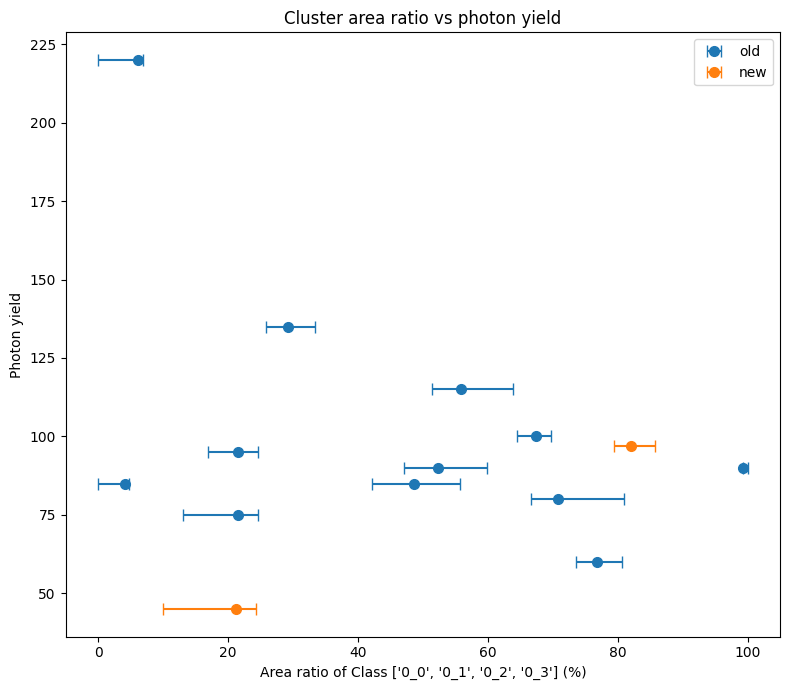

In [49]:
# area ratio with systematic error
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt

# class_groups = {
#     "fine crystal": ["0_0", "0_1", "0_2", "0_3"],
#     "elongated crystal": ["10", "11", "12"],
#     "plate-like crystal": ["200_0", "200_1", "201", "21_0", "21_1", "21_2", "21_3"],
#     "empty": ["30_0", "30_1", "30_2", "30_3", "31", "32"],
# }
target_classes = ["0_0", "0_1", "0_2", "0_3"]

rf_csv = "/home/kmanabe2403/document/dune/superpixel/data/pipeline_output/RF_results4_corrected/Subclass_GMM/Subclass_GMM_GMM_area_ratio.csv"
photon_csv = "/home/kmanabe2403/document/dune/superpixel/photon_yield.csv"

df = pd.read_csv(rf_csv)
df["group"] = [item["group"] for item in image_paths]
df["plate"] = [item["plate"] for item in image_paths]

area_cols = [f"class_{c}_area_ratio" for c in target_classes]
for col in area_cols:
    if col not in df.columns: raise ValueError(f"{col} is not in RF CSV")

df["target_area_ratio"] = df[area_cols].fillna(0).sum(axis=1)

# --- Photon yield ---
photon_df = pd.read_csv(photon_csv)
photon_df.columns = photon_df.columns.str.strip()
photon_df["Type"] = photon_df["Type"].astype(str).str.strip()
photon_df["plate"] = photon_df["plate"].astype(str).str.strip().str.replace(" ", "", regex=False)
photon_df["plate"] = photon_df["plate"].apply(lambda x: f"pl{int(float(x)):02d}")

results = []
for (group, plate), plate_df in df.groupby(["group", "plate"]):
    values = plate_df["target_area_ratio"].dropna().values
    n_images = len(values)
    if n_images == 0: continue

    # --- Calculate systematic error using leave-one-out means ---
    mean_8 = np.mean(values)
    if n_images >= 7:
        leave_one_out_means = np.array([np.mean(np.delete(values, i)) for i in range(n_images)])
        ci_low = np.min(leave_one_out_means)
        ci_high = np.max(leave_one_out_means)
        ci_half = (ci_high - ci_low) / 2
    else:
        ci_low = np.nan
        ci_high = np.nan
        ci_half = np.nan

    results.append({
        "group": group, "plate": plate, "n_images": n_images, "mean": mean_8,
        "ci_low": ci_low, "ci_high": ci_high, "ci_half": ci_half
    })

stability_df = pd.DataFrame(results)

# --- Merge with photon yield ---
plot_df = pd.merge(stability_df, photon_df, left_on=["group", "plate"], right_on=["Type", "plate"], how="inner")
plot_df = plot_df[plot_df["mean"] > 3].copy()

print(plot_df[["group", "plate", "n_images", "mean", "ci_low", "ci_high", "ci_half", "photon_yield"]].to_string(index=False))

# --- Error bars ---
plot_df["error_low"] = plot_df["mean"] - plot_df["ci_low"]
plot_df["error_high"] = plot_df["ci_high"] - plot_df["mean"]

plt.figure(figsize=(8, 7))
for group in target_plates.keys():
    data = plot_df[plot_df["group"] == group]
    plt.errorbar(data["mean"], data["photon_yield"], xerr=[data["error_low"], data["error_high"]], fmt="o", markersize=7, capsize=4, label=group)

plt.xlabel(f"Area ratio of Class {target_classes} (%)")
plt.ylabel("Photon yield")
plt.title("Cluster area ratio vs photon yield")
# plt.grid()
plt.legend()
plt.tight_layout()
plt.show()


Area ratio uncertainty from 8 -> 7 images:
group plate  n_images  fine crystal_error  elongated crystal_error  plate-like crystal_error  empty_error
  new  pl01         8            0.000000                 0.000000                  0.000000     0.000000
  new  pl02         8            0.071429                 0.071429                  0.015599     0.000000
  new  pl04         8            0.000000                 0.000000                  0.000000     0.000000
  new  pl05         8            0.000000                 0.000000                  0.000000     0.000000
  new  pl06         8            0.000000                 0.000000                  0.000000     0.000000
  new  pl07         8            0.000000                 0.070248                  0.071429     0.031401
  new  pl08         8            0.000000                 0.000000                  0.000000     0.000000
  new  pl09         8            0.000000                 0.000000                  0.000000     0.000000
  

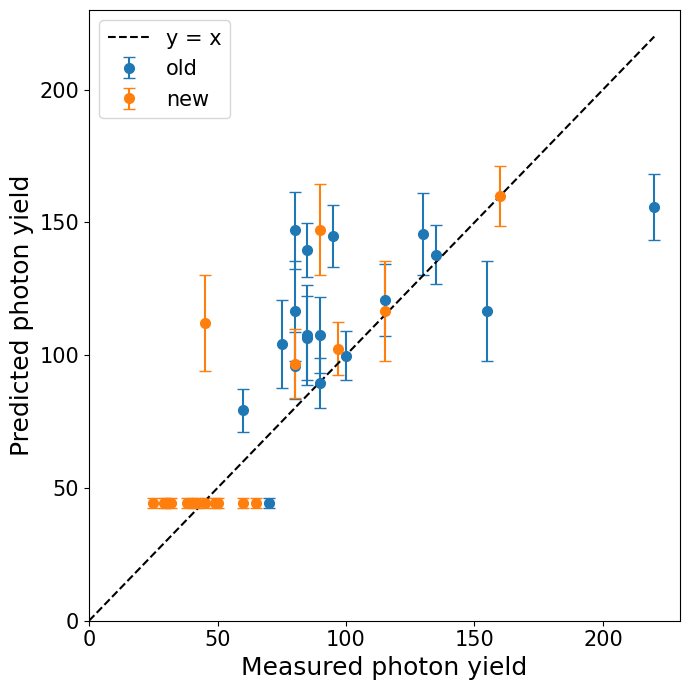

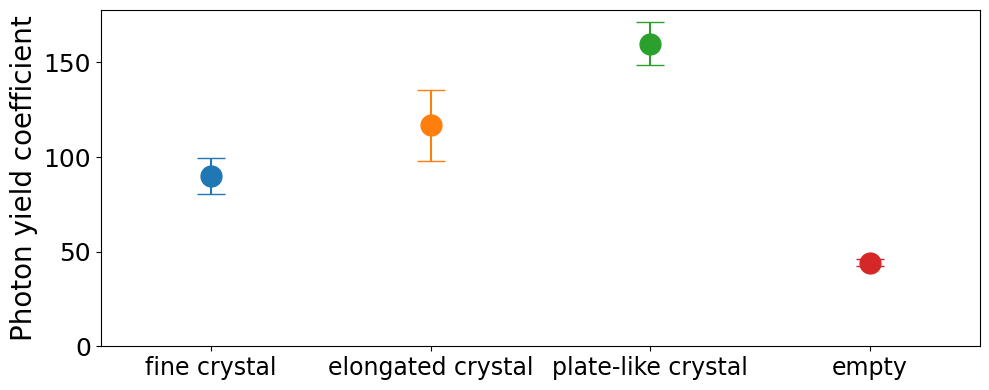

In [ ]:
# photon yield model
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import lsq_linear
from sklearn.metrics import r2_score, mean_squared_error

rf_csv = "/home/kmanabe2403/document/dune/superpixel/data/pipeline_output/RF_results4_corrected/Subclass_GMM/Subclass_GMM_GMM_area_ratio.csv"
photon_csv = "/home/kmanabe2403/document/dune/superpixel/photon_yield.csv"

df = pd.read_csv(rf_csv)

# --- Match group/plate/name using image_id ---
image_info = {i: item for i, item in enumerate(image_paths)}
df["group"] = df["image_id"].map(lambda i: image_info[i]["group"])
df["plate"] = df["image_id"].map(lambda i: image_info[i]["plate"])
df["name"] = df["image_id"].map(lambda i: image_info[i]["name"])

class_groups = {
    "Class 0": ["0_0"],
    "Class 1": ["0_1"],
    "Class 2": ["0_2"],
    "Class 3": ["0_3"],
    "Class 4": ["10"],
    "Class 5": ["11"],
    "Class 6": ["12"],
    "Class 7": ["200_0"],
    "Class 8": ["200_1"],
    "Class 9": ["201"],
    "Class 10": ["21_0"],
    "Class 11": ["21_1"],
    "Class 12": ["21_2"],
    "Class 13": ["21_3"],
    "Class 14": ["30_0"],
    "Class 15": ["30_1"],
    "Class 16": ["30_2"],
    "Class 17": ["30_3"],
    "Class 18": ["31"],
    "Class 19": ["32"],
}

class_groups = {
    "fine crystal": ["0_0", "0_1", "0_2", "0_3"],
    "elongated crystal": ["10", "11", "12"],
    "plate-like crystal": ["200_0", "200_1", "201", "21_0", "21_1", "21_2", "21_3"],
    "empty": ["30_0", "30_1", "30_2", "30_3", "31", "32"],
}

# class_groups = {
#     "Class 0": ["0_0", "0_2", "0_3"],
#     "Class 1": ["10", "11"],
#     "Class 1": ["0_1", "12"],
#     "Class 2": ["200_0", "200_1", "201", "21_0", "21_1", "21_2", "21_3"],
#     "Class 3": ["30_1", "30_2"],
#     "Class 4": ["30_0", "30_3", "31", "32"],
# }

# --- Calculate class area ratios ---
for name, classes in class_groups.items():
    cols = [f"class_{c}_area_ratio" for c in classes if f"class_{c}_area_ratio" in df.columns]
    df[name] = df[cols].sum(axis=1) if cols else 0.0

group_cols = list(class_groups.keys())

# --- 1. Area ratio uncertainty from 8 -> 7 images ---
plate_records = []
area_error_records = []

for (group, plate), d in df.groupby(["group", "plate"]):
    d = d.reset_index(drop=True)
    n_images = len(d)

    if n_images < 2:
        print(f"WARNING: {group}/{plate}: only {n_images} images")
        continue

    mean_values = d[group_cols].mean().values
    loo_image_means = []

    for i in range(n_images):
        d_subset = d.drop(index=i)
        loo_image_means.append(d_subset[group_cols].mean().values)

    loo_image_means = np.asarray(loo_image_means)
    area_error = (loo_image_means.max(axis=0) - loo_image_means.min(axis=0)) / 2.0

    record = {"group": group, "plate": plate}
    error_record = {"group": group, "plate": plate, "n_images": n_images}

    for j, name in enumerate(group_cols):
        record[f"{name}_mean"] = mean_values[j]
        error_record[f"{name}_error"] = area_error[j]

    plate_records.append(record)
    area_error_records.append(error_record)

plate_area_df = pd.DataFrame(plate_records)
area_error_df = pd.DataFrame(area_error_records)

# --- Convert area ratio from % to 0-1 if necessary ---
for name in group_cols:
    if plate_area_df[f"{name}_mean"].max() > 1:
        plate_area_df[f"{name}_mean"] /= 100
        area_error_df[f"{name}_error"] /= 100

mean_cols = [f"{name}_mean" for name in group_cols]
area_error_cols = [f"{name}_error" for name in group_cols]

print("\nArea ratio uncertainty from 8 -> 7 images:")
print(area_error_df.to_string(index=False))

# --- Photon yield ---
photon_df = pd.read_csv(photon_csv)
photon_df.columns = photon_df.columns.str.strip()
photon_df["Type"] = photon_df["Type"].astype(str).str.strip()
photon_df["plate"] = photon_df["plate"].astype(str).str.strip().str.replace(" ", "", regex=False)
photon_df["plate"] = photon_df["plate"].apply(lambda x: f"pl{int(float(x)):02d}")

plot_df = pd.merge(plate_area_df, area_error_df, on=["group", "plate"], how="inner")
plot_df = pd.merge(plot_df, photon_df, left_on=["group", "plate"], right_on=["Type", "plate"], how="inner")

print("\nPlate data:")
print(plot_df[["group", "plate"] + mean_cols + area_error_cols + ["photon_yield"]].to_string(index=False))

# --- 2. Weighted regression using area uncertainty ---
X = plot_df[mean_cols].fillna(0).values
y = plot_df["photon_yield"].values
area_error = plot_df[area_error_cols].fillna(0).values

combined_area_error = np.sqrt(np.sum(area_error**2, axis=1))
positive_error = combined_area_error[combined_area_error > 0]

if len(positive_error) == 0:
    combined_area_error[:] = 1.0
else:
    combined_area_error[combined_area_error == 0] = np.min(positive_error)

weights = 1.0 / combined_area_error**2
X_weighted = X * np.sqrt(weights[:, None])
y_weighted = y * np.sqrt(weights)

result = lsq_linear(X_weighted, y_weighted, bounds=(0, 500))
coef = result.x
y_pred = X @ coef

r2 = r2_score(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))

# --- 3. Leave-one-plate-out coefficient ---
loo_coefs = []

for i in range(len(y)):
    mask = np.ones(len(y), dtype=bool)
    mask[i] = False

    X_loo = X[mask]
    y_loo = y[mask]
    error_loo = combined_area_error[mask]

    weights_loo = 1.0 / error_loo**2
    X_loo_weighted = X_loo * np.sqrt(weights_loo[:, None])
    y_loo_weighted = y_loo * np.sqrt(weights_loo)

    result_loo = lsq_linear(X_loo_weighted, y_loo_weighted, bounds=(0, 500))
    loo_coefs.append(result_loo.x)

loo_coefs = np.asarray(loo_coefs)

# --- LOO coefficient variation ---
coef_error = (np.max(loo_coefs, axis=0) - np.min(loo_coefs, axis=0)) / 2.0

print("\nConstrained weighted regression:")
for name, c, e in zip(group_cols, coef, coef_error):
    print(f"{name:10s}: {c:.4f} +/- {e:.4f}")

print(f"R²   = {r2:.4f}")
print(f"RMSE = {rmse:.4f}")

print("\nLOO coefficient range:")
for j, name in enumerate(group_cols):
    print(f"{name:10s}: {loo_coefs[:, j].min():.4f} - {loo_coefs[:, j].max():.4f}")

# --- Class contribution ---
for name, c in zip(group_cols, coef):
    plot_df[f"{name}_contribution"] = plot_df[f"{name}_mean"] * c

contribution_cols = [f"{name}_contribution" for name in group_cols]
plot_df["predicted_photon_yield"] = plot_df[contribution_cols].sum(axis=1)

# --- 4. Propagate predicted photon yield uncertainty ---
X_mean = plot_df[mean_cols].fillna(0).values

predicted_error_area = np.sqrt(np.sum((coef[None, :] * area_error)**2, axis=1))
predicted_error_coef = np.sqrt(np.sum((X_mean * coef_error[None, :])**2, axis=1))
predicted_error_total = np.sqrt(predicted_error_area**2 + predicted_error_coef**2)

plot_df["predicted_error_area"] = predicted_error_area
plot_df["predicted_error_coef"] = predicted_error_coef
plot_df["predicted_photon_yield_error"] = predicted_error_total

for name in group_cols:
    plot_df[f"{name}_contribution_ratio"] = plot_df[f"{name}_contribution"] / plot_df["predicted_photon_yield"]

print("\nPrediction uncertainty:")
print(plot_df[["group", "plate", "predicted_photon_yield", "predicted_error_area", "predicted_error_coef", "predicted_photon_yield_error"]].to_string(index=False))

# --- Measured vs predicted ---
plt.figure(figsize=(7, 7))

for group in target_plates.keys():
    mask = plot_df["group"] == group
    plt.errorbar(plot_df.loc[mask, "photon_yield"], plot_df.loc[mask, "predicted_photon_yield"], yerr=plot_df.loc[mask, "predicted_photon_yield_error"], fmt="o", markersize=7, capsize=4, label=group)

xmin = min(y.min(), y_pred.min())
xmax = max(y.max(), y_pred.max())

plt.plot([0, xmax], [0, xmax], "--", color="black", label="y = x")
plt.xlabel("Measured photon yield", fontsize=18)
plt.ylabel("Predicted photon yield", fontsize=18)
# plt.title("Measured vs predicted photon yield")
plt.xticks(np.arange(0, 225, 50), fontsize=15)
plt.yticks(np.arange(0, 225, 50), fontsize=15)

# plt.text(
#     0.05,
#     0.95,
#     f"$R^2$ = {r2:.3f}\nRMSE = {rmse:.3f}",
#     transform=plt.gca().transAxes,
#     verticalalignment="top"
# )
plt.xlim(0, 230)
plt.ylim(0, 230)

# plt.grid()
plt.legend(fontsize=15)
plt.tight_layout()
plt.show()

# --- Contribution ---
ratio_cols = [f"{name}_contribution_ratio" for name in group_cols]
class_numbers = np.arange(len(group_cols))
colors = ["C0", "C1", "C2", "C3"]

plt.figure(figsize=(10, 4))
for i, (x, y, err) in enumerate(zip(class_numbers, coef, coef_error)):
    plt.errorbar(x, y, yerr=err, fmt="o", markersize=15, capsize=10, color=colors[i])

plt.ylabel("Photon yield coefficient", fontsize=20)
plt.xticks(class_numbers, group_cols, fontsize=17)
plt.yticks(np.arange(0, 151, 50), fontsize=18)
plt.xlim(-0.5, len(class_numbers) - 0.5)
plt.tight_layout()
plt.show()


Area ratio uncertainty from 8 -> 7 images:
group plate  n_images  fine crystal_error  elongated crystal_error  plate-like crystal_error  empty_error
  new  pl01         8            0.000000                 0.000000                  0.000000     0.000000
  new  pl02         8            0.071429                 0.071429                  0.015599     0.000000
  new  pl04         8            0.000000                 0.000000                  0.000000     0.000000
  new  pl05         8            0.000000                 0.000000                  0.000000     0.000000
  new  pl06         8            0.000000                 0.000000                  0.000000     0.000000
  new  pl07         8            0.000000                 0.070248                  0.071429     0.031401
  new  pl08         8            0.000000                 0.000000                  0.000000     0.000000
  new  pl09         8            0.000000                 0.000000                  0.000000     0.000000
  

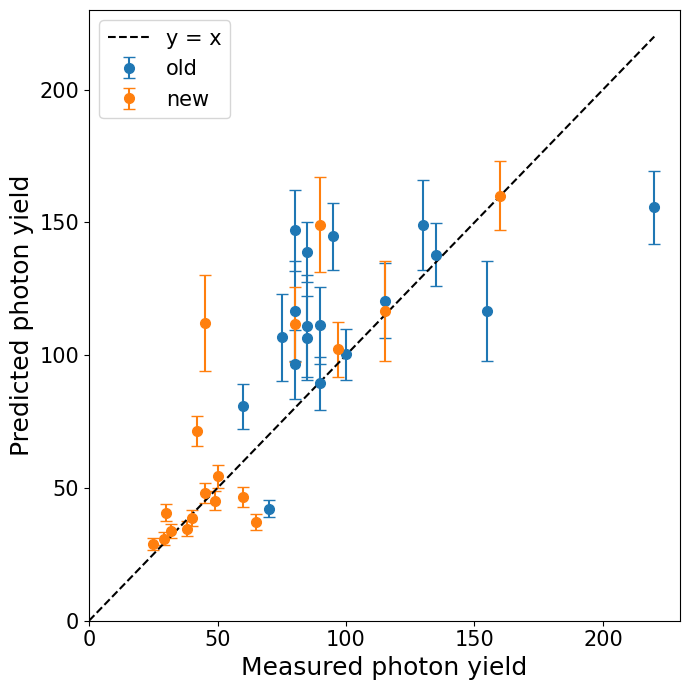

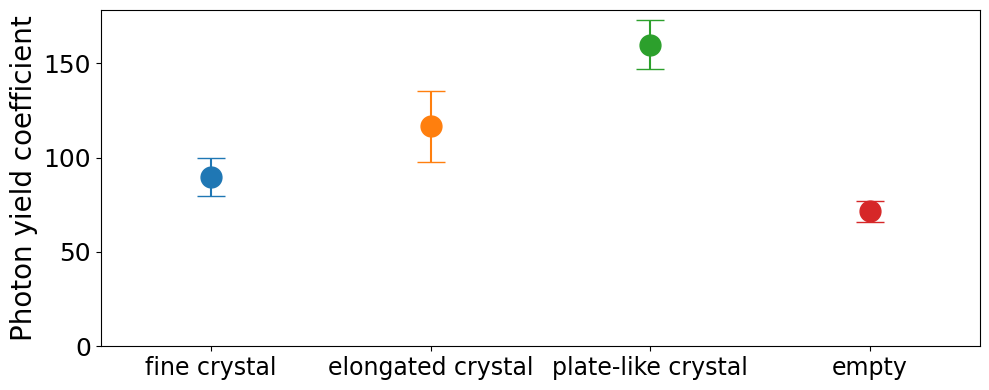

In [51]:
# photon yield model with coverage
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import lsq_linear
from sklearn.metrics import r2_score, mean_squared_error

rf_csv = "/home/kmanabe2403/document/dune/superpixel/data/pipeline_output/RF_results4_corrected/Subclass_GMM/Subclass_GMM_GMM_area_ratio.csv"
photon_csv = "/home/kmanabe2403/document/dune/superpixel/photon_yield.csv"
gmm_area_path = os.path.join(data_root, "coverage_output_data2", "result", "coverage_GMM_cluster", "gmm_area_results.csv")
gmm_settings_path = os.path.join(data_root, "coverage_output_data2", "result", "gmm_settings.csv")

df = pd.read_csv(rf_csv)

# --- Match group/plate/name using image_id ---
image_info = {i: item for i, item in enumerate(image_paths)}
df["group"] = df["image_id"].map(lambda i: image_info[i]["group"])
df["plate"] = df["image_id"].map(lambda i: image_info[i]["plate"])
df["name"] = df["image_id"].map(lambda i: image_info[i]["name"])

class_groups = {
    "fine crystal": ["0_0", "0_1", "0_2", "0_3"],
    "elongated crystal": ["10", "11", "12"],
    "plate-like crystal": ["200_0", "200_1", "201", "21_0", "21_1", "21_2", "21_3"],
    "empty": ["30_0", "30_1", "30_2", "30_3", "31", "32"],
}

# --- Class area ratio ---
for name, classes in class_groups.items():
    cols = [f"class_{c}_area_ratio" for c in classes if f"class_{c}_area_ratio" in df.columns]
    df[name] = df[cols].sum(axis=1) if cols else 0.0

group_cols = list(class_groups.keys())

# --- 8 images -> 7 images area ratio uncertainty ---
plate_records = []
area_error_records = []

for (group, plate), d in df.groupby(["group", "plate"]):
    d = d.reset_index(drop=True)
    n_images = len(d)
    if n_images < 2:
        print(f"WARNING: {group}/{plate}: only {n_images} images")
        continue

    mean_values = d[group_cols].mean().values
    loo_image_means = []

    for i in range(n_images):
        d_subset = d.drop(index=i)
        loo_image_means.append(d_subset[group_cols].mean().values)

    loo_image_means = np.asarray(loo_image_means)
    area_error = (loo_image_means.max(axis=0) - loo_image_means.min(axis=0)) / 2.0

    record = {"group": group, "plate": plate}
    error_record = {"group": group, "plate": plate, "n_images": n_images}

    for j, name in enumerate(group_cols):
        record[f"{name}_mean"] = mean_values[j]
        error_record[f"{name}_error"] = area_error[j]

    plate_records.append(record)
    area_error_records.append(error_record)

plate_area_df = pd.DataFrame(plate_records)
area_error_df = pd.DataFrame(area_error_records)

# --- Convert area ratio from % to 0-1 if necessary ---
for name in group_cols:
    if plate_area_df[f"{name}_mean"].max() > 1:
        plate_area_df[f"{name}_mean"] /= 100
        area_error_df[f"{name}_error"] /= 100

mean_cols = [f"{name}_mean" for name in group_cols]
area_error_cols = [f"{name}_error" for name in group_cols]

print("\nArea ratio uncertainty from 8 -> 7 images:")
print(area_error_df.to_string(index=False))

# --- Photon yield ---
photon_df = pd.read_csv(photon_csv)
photon_df.columns = photon_df.columns.str.strip()
photon_df["Type"] = photon_df["Type"].astype(str).str.strip()
photon_df["plate"] = photon_df["plate"].astype(str).str.strip().str.replace(" ", "", regex=False)
photon_df["plate"] = photon_df["plate"].apply(lambda x: f"pl{int(float(x)):02d}")

plot_df = pd.merge(plate_area_df, area_error_df, on=["group", "plate"], how="inner")
plot_df = pd.merge(plot_df, photon_df, left_on=["group", "plate"], right_on=["Type", "plate"], how="inner")

# --- Calculate coverage ---
df_area = pd.read_csv(gmm_area_path)
df_settings = pd.read_csv(gmm_settings_path)
df_area.columns = df_area.columns.str.strip()
df_settings.columns = df_settings.columns.str.strip()

def is_valid(x):
    return pd.notna(x) and str(x).strip() != ""

coverage_results = []

for _, setting in df_settings.iterrows():
    image_id = int(setting["imageID"])
    group = str(setting["group"]).strip()
    plate = str(setting["plate"]).strip()
    name = str(setting["name"]).strip()
    gmm_label = int(setting["GMMlabel"]) if is_valid(setting["GMMlabel"]) else None
    cluster_ids = []

    if is_valid(setting["cluster"]):
        try:
            cluster_ids = [int(x.strip()) for x in str(setting["cluster"]).split(",") if x.strip() != ""]
        except ValueError:
            continue

    fluction = float(setting["fluction"]) if is_valid(setting["fluction"]) else None

    # --- Determine empty from cluster ---
    if len(cluster_ids) > 0:
        if gmm_label is None:
            continue

        match = df_area[(df_area["image_id"] == image_id) & (df_area["group"] == group) & (df_area["plate"] == plate) & (df_area["gmm_label"] == gmm_label) & (df_area["cluster_id"].isin(cluster_ids))]
        found_clusters = set(match["cluster_id"].astype(int))

        if not set(cluster_ids).issubset(found_clusters):
            continue

        empty_ratio = match["area_ratio"].sum()
        source = "cluster"

    # --- Determine empty from fluction ---
    elif fluction is not None:
        empty_ratio = fluction
        source = "fluction"
    else:
        continue

    coverage = 1.0 - empty_ratio
    coverage_results.append({"image_id": image_id, "group": group, "plate": plate, "name": name, "coverage": coverage, "source": source})

df_coverage = pd.DataFrame(coverage_results)

# --- Plate coverage ---
M = 1
coverage_plate_records = []

for (group, plate, source), subset in df_coverage.groupby(["group", "plate", "source"]):
    coverage_values = subset["coverage"].dropna().values
    n = len(coverage_values)
    if n <= M:
        continue

    coverage = np.mean(coverage_values)
    leave_one_out = []

    for i in range(n):
        selected = np.delete(coverage_values, i)
        leave_one_out.append(np.mean(selected))

    leave_one_out = np.asarray(leave_one_out)
    coverage_plate_records.append({"group": group, "plate": plate, "source": source, "coverage": coverage, "coverage_min": leave_one_out.min(), "coverage_max": leave_one_out.max(), "n_images": n})

coverage_df = pd.DataFrame(coverage_plate_records)

# --- Use only cluster-based coverage ---
coverage_df = coverage_df[coverage_df["source"] == "cluster"].copy()

# --- Photon yield + coverage ---
plot_df = plot_df.merge(coverage_df[["group", "plate", "coverage", "coverage_min", "coverage_max", "n_images"]], on=["group", "plate"], how="left")
plot_df = plot_df.dropna(subset=["photon_yield"])

print("\nPlate data:")
print(plot_df[["group", "plate"] + mean_cols + ["coverage", "photon_yield"]].to_string(index=False))

# --- Weighted regression using empty × coverage ---
plot_df["empty_fit"] = plot_df["empty_mean"]
has_coverage = plot_df["coverage"].notna()
plot_df.loc[has_coverage, "empty_fit"] = plot_df.loc[has_coverage, "empty_mean"] * plot_df.loc[has_coverage, "coverage"]

fit_cols = ["fine crystal_mean", "elongated crystal_mean", "plate-like crystal_mean", "empty_fit"]

X = plot_df[fit_cols].fillna(0).values
y = plot_df["photon_yield"].values

# --- Area uncertainty ---
area_error_fit = plot_df[["fine crystal_error", "elongated crystal_error", "plate-like crystal_error", "empty_error"]].fillna(0).values
area_error_fit[has_coverage.values, 3] *= plot_df.loc[has_coverage, "coverage"].values

combined_area_error = np.sqrt(np.sum(area_error_fit**2, axis=1))
positive_error = combined_area_error[combined_area_error > 0]

if len(positive_error) == 0:
    combined_area_error[:] = 1.0
else:
    combined_area_error[combined_area_error == 0] = np.min(positive_error)

weights = 1.0 / combined_area_error**2
X_weighted = X * np.sqrt(weights[:, None])
y_weighted = y * np.sqrt(weights)

result = lsq_linear(X_weighted, y_weighted, bounds=(0, 500))
coef = result.x
y_pred = X @ coef

r2 = r2_score(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))

# --- Leave-one-plate-out coefficient ---
loo_coefs = []

for i in range(len(y)):
    mask = np.ones(len(y), dtype=bool)
    mask[i] = False
    X_loo = X[mask]
    y_loo = y[mask]
    error_loo = combined_area_error[mask]
    weights_loo = 1.0 / error_loo**2
    X_loo_weighted = X_loo * np.sqrt(weights_loo[:, None])
    y_loo_weighted = y_loo * np.sqrt(weights_loo)
    result_loo = lsq_linear(X_loo_weighted, y_loo_weighted, bounds=(0, 500))
    loo_coefs.append(result_loo.x)

loo_coefs = np.asarray(loo_coefs)
coef_error = (np.max(loo_coefs, axis=0) - np.min(loo_coefs, axis=0)) / 2.0

print("\nWeighted regression with empty × coverage")
for name, c, e in zip(["fine crystal", "elongated crystal", "plate-like crystal", "empty"], coef, coef_error):
    print(f"{name:20s}: {c:.4f} +/- {e:.4f}")
print(f"R²   = {r2:.4f}")
print(f"RMSE = {rmse:.4f}")

# --- Class contribution ---
plot_df["fine crystal_contribution"] = plot_df["fine crystal_mean"] * coef[0]
plot_df["elongated crystal_contribution"] = plot_df["elongated crystal_mean"] * coef[1]
plot_df["plate-like crystal_contribution"] = plot_df["plate-like crystal_mean"] * coef[2]
plot_df["empty_contribution"] = plot_df["empty_fit"] * coef[3]

contribution_cols = ["fine crystal_contribution", "elongated crystal_contribution", "plate-like crystal_contribution", "empty_contribution"]
plot_df["predicted_photon_yield"] = plot_df[contribution_cols].sum(axis=1)

# --- Predicted photon yield uncertainty ---
X_mean = plot_df[fit_cols].fillna(0).values
predicted_error_area = np.sqrt(np.sum((coef[None, :] * area_error_fit)**2, axis=1))
predicted_error_coef = np.sqrt(np.sum((X_mean * coef_error[None, :])**2, axis=1))
predicted_error_total = np.sqrt(predicted_error_area**2 + predicted_error_coef**2)

plot_df["predicted_error_area"] = predicted_error_area
plot_df["predicted_error_coef"] = predicted_error_coef
plot_df["predicted_photon_yield_error"] = predicted_error_total

# --- Contribution ratio ---
for name in ["fine crystal", "elongated crystal", "plate-like crystal", "empty"]:
    plot_df[f"{name}_contribution_ratio"] = plot_df[f"{name}_contribution"] / plot_df["predicted_photon_yield"]

print("\nPrediction:")
print(plot_df[["group", "plate", "coverage", "photon_yield", "predicted_photon_yield", "predicted_photon_yield_error"] + contribution_cols].to_string(index=False))

# --- Measured vs predicted ---
plt.figure(figsize=(7, 7))

for group in target_plates.keys():
    mask = plot_df["group"] == group
    plt.errorbar(plot_df.loc[mask, "photon_yield"], plot_df.loc[mask, "predicted_photon_yield"], yerr=plot_df.loc[mask, "predicted_photon_yield_error"], fmt="o", markersize=7, capsize=4, label=group)

xmin = min(y.min(), y_pred.min())
xmax = max(y.max(), y_pred.max())

plt.plot([0, xmax], [0, xmax], "--", color="black", label="y = x")
plt.xlabel("Measured photon yield", fontsize=18)
plt.ylabel("Predicted photon yield", fontsize=18)
# plt.title("Measured vs predicted photon yield")
plt.xticks(np.arange(0, 225, 50), fontsize=15)
plt.yticks(np.arange(0, 225, 50), fontsize=15)
# plt.text(0.05, 0.95, f"$R^2$ = {r2:.3f}\nRMSE = {rmse:.3f}", transform=plt.gca().transAxes, verticalalignment="top")
plt.xlim(0, 230)
plt.ylim(0, 230)
# plt.grid()
plt.legend(fontsize=15)
plt.tight_layout()
plt.show()

# --- Coefficient ---
class_numbers = np.arange(len(group_cols))
colors = ["C0", "C1", "C2", "C3"]

plt.figure(figsize=(10, 4))
for i, (x, y_c, err) in enumerate(zip(class_numbers, coef, coef_error)):
    plt.errorbar(x, y_c, yerr=err, fmt="o", markersize=15, capsize=10, color=colors[i])

plt.ylabel("Photon yield coefficient", fontsize=20)
plt.xticks(class_numbers, group_cols, fontsize=17)
plt.yticks(np.arange(0, 151, 50), fontsize=18)
plt.xlim(-0.5, len(class_numbers) - 0.5)
plt.tight_layout()
plt.show()

In [ ]:
# 

In [ ]:
# 

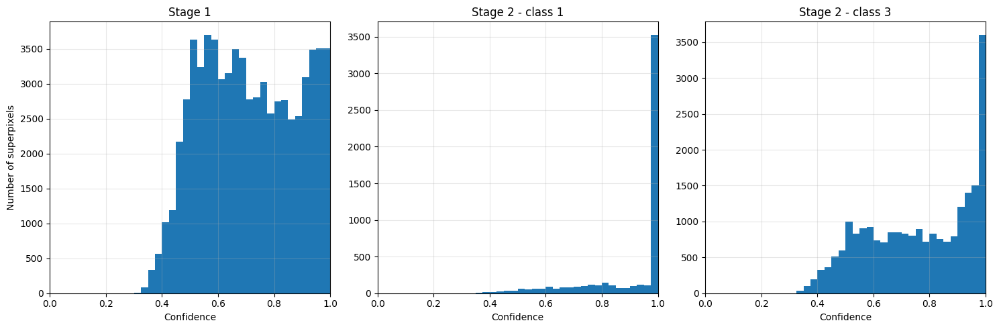

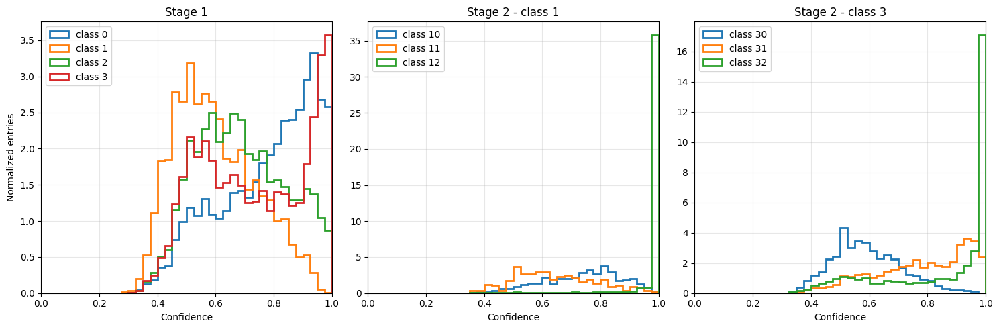

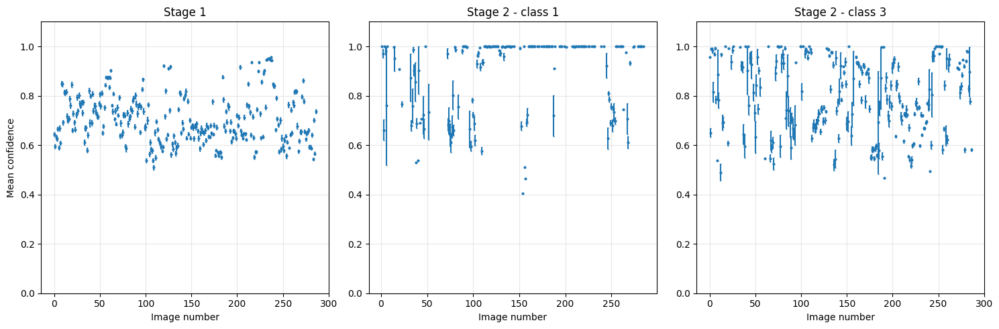

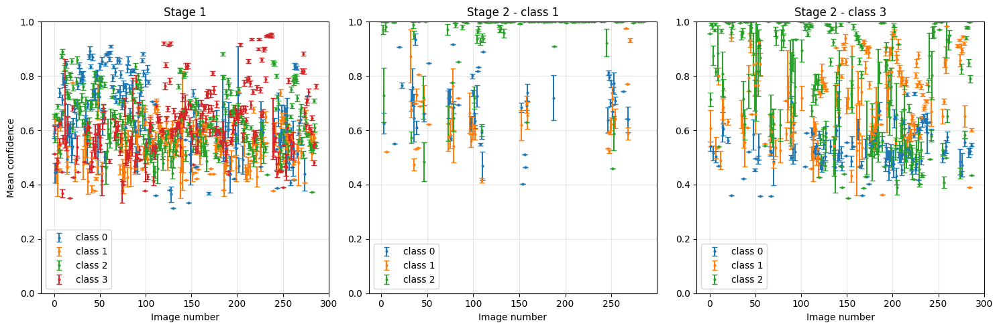

In [ ]:
# appendix
# # plot：confidence
# def plot_rf_confidence(image_paths, path_for_data):
#     n_images = len(image_paths)
#     image_numbers = np.arange(n_images)
#     stage1_conf_all, stage1_class_all = [], []
#     stage2_conf_all, stage2_label_all = {1: [], 3: []}, {1: [], 3: []}

#     for image_id in image_numbers:
#         stage1_conf_all.append(np.load(os.path.join(result_dir, f"rf_confidence_{image_id:04d}.npy")))
#         stage1_class_all.append(np.load(os.path.join(result_dir, f"rf_labels_{image_id:04d}.npy")))
#         for class_id in [1, 3]:
#             p1 = os.path.join(result_dir, f"rf_stage2_class{class_id}_confidence_{image_id:04d}.npy")
#             p2 = os.path.join(result_dir, f"rf_stage2_class{class_id}_labels_{image_id:04d}.npy")
#             stage2_conf_all[class_id].append(np.load(p1) if os.path.exists(p1) else np.array([]))
#             stage2_label_all[class_id].append(np.load(p2) if os.path.exists(p2) else np.array([]))

#     stage1_conf = np.concatenate(stage1_conf_all)
#     stage1_class = np.concatenate(stage1_class_all)
#     stage2_conf = {i: np.concatenate([x for x in stage2_conf_all[i] if len(x)]) if any(len(x) for x in stage2_conf_all[i]) else np.array([]) for i in [1, 3]}
#     stage2_label = {i: np.concatenate([x for x in stage2_label_all[i] if len(x)]) if any(len(x) for x in stage2_label_all[i]) else np.array([]) for i in [1, 3]}
#     bins = np.linspace(0, 1, 41)

#     # 1. confidence histogramを3枚横並び
#     fig, axes = plt.subplots(1, 3, figsize=(15, 5))

#     axes[0].hist(stage1_conf, bins=bins)
#     axes[0].set_title("Stage 1")
#     axes[0].set_xlabel("Confidence")
#     axes[0].set_ylabel("Number of superpixels")
#     axes[0].set_xlim(0, 1)
#     axes[0].grid(alpha=0.3)

#     axes[1].hist(stage2_conf[1], bins=bins)
#     axes[1].set_title("Stage 2 - class 1")
#     axes[1].set_xlabel("Confidence")
#     axes[1].set_xlim(0, 1)
#     axes[1].grid(alpha=0.3)

#     axes[2].hist(stage2_conf[3], bins=bins)
#     axes[2].set_title("Stage 2 - class 3")
#     axes[2].set_xlabel("Confidence")
#     axes[2].set_xlim(0, 1)
#     axes[2].grid(alpha=0.3)

#     plt.tight_layout()
#     plt.savefig(os.path.join(result_dir, "confidence_histogram_3stages.png"), dpi=300)
#     plt.show()

#     # 2. クラスごとの規格化step histogramを3枚横並び
#     fig, axes = plt.subplots(1, 3, figsize=(15, 5))

#     for class_id in sorted(np.unique(stage1_class)):
#         mask = stage1_class == class_id
#         axes[0].hist(stage1_conf[mask], bins=bins, density=True, histtype="step", linewidth=2, label=f"class {class_id}")
#     axes[0].set_title("Stage 1")
#     axes[0].set_xlabel("Confidence")
#     axes[0].set_ylabel("Normalized entries")
#     axes[0].set_xlim(0, 1)
#     axes[0].legend()
#     axes[0].grid(alpha=0.3)

#     for class_id in sorted(np.unique(stage2_label[1])) if len(stage2_label[1]) else []:
#         mask = stage2_label[1] == class_id
#         axes[1].hist(stage2_conf[1][mask], bins=bins, density=True, histtype="step", linewidth=2, label=f"class 1{class_id}")
#     axes[1].set_title("Stage 2 - class 1")
#     axes[1].set_xlabel("Confidence")
#     axes[1].set_xlim(0, 1)
#     axes[1].legend()
#     axes[1].grid(alpha=0.3)

#     for class_id in sorted(np.unique(stage2_label[3])) if len(stage2_label[3]) else []:
#         mask = stage2_label[3] == class_id
#         axes[2].hist(stage2_conf[3][mask], bins=bins, density=True, histtype="step", linewidth=2, label=f"class 3{class_id}")
#     axes[2].set_title("Stage 2 - class 3")
#     axes[2].set_xlabel("Confidence")
#     axes[2].set_xlim(0, 1)
#     axes[2].legend()
#     axes[2].grid(alpha=0.3)

#     plt.tight_layout()
#     plt.savefig(os.path.join(result_dir, "confidence_histogram_normalized_step_3stages.png"), dpi=300)
#     plt.show()

#     # 3. 画像ごとの平均confidenceを3枚横並び
#     means, errors = {}, {}
#     for key in ["stage1", 1, 3]:
#         means[key], errors[key] = [], []
#         for i in image_numbers:
#             values = stage1_conf_all[i] if key == "stage1" else stage2_conf_all[key][i]
#             if len(values):
#                 means[key].append(np.mean(values))
#                 errors[key].append(np.std(values, ddof=1) / np.sqrt(len(values)) if len(values) > 1 else 0)
#             else:
#                 means[key].append(np.nan)
#                 errors[key].append(np.nan)

#     fig, axes = plt.subplots(1, 3, figsize=(15, 5))

#     axes[0].errorbar(image_numbers, means["stage1"], yerr=errors["stage1"], fmt="o", ms=2, capsize=1)
#     axes[0].set_title("Stage 1")
#     axes[0].set_xlabel("Image number")
#     axes[0].set_ylabel("Mean confidence")
#     axes[0].set_ylim(0, 1.1)
#     axes[0].grid(alpha=0.3)

#     axes[1].errorbar(image_numbers, means[1], yerr=errors[1], fmt="o", ms=2, capsize=1)
#     axes[1].set_title("Stage 2 - class 1")
#     axes[1].set_xlabel("Image number")
#     axes[1].set_ylim(0, 1.1)
#     axes[1].grid(alpha=0.3)

#     axes[2].errorbar(image_numbers, means[3], yerr=errors[3], fmt="o", ms=2, capsize=1)
#     axes[2].set_title("Stage 2 - class 3")
#     axes[2].set_xlabel("Image number")
#     axes[2].set_ylim(0, 1.1)
#     axes[2].grid(alpha=0.3)

#     plt.tight_layout()
#     plt.savefig(os.path.join(result_dir, "mean_confidence_vs_image_3stages.png"), dpi=300)
#     plt.show()

#     # 4. クラスごとの平均confidence
#     fig, axes = plt.subplots(1, 3, figsize=(15, 5))

#     def plot_class_means(ax, conf_all, label_all, class_ids, prefix):
#         for class_id in class_ids:
#             mean, error = [], []
#             for i in image_numbers:
#                 values = conf_all[i][label_all[i] == class_id]
#                 if len(values):
#                     mean.append(np.mean(values))
#                     error.append(np.std(values, ddof=1) / np.sqrt(len(values)) if len(values) > 1 else 0)
#                 else:
#                     mean.append(np.nan)
#                     error.append(np.nan)
#             ax.errorbar(image_numbers, mean, yerr=error, fmt="o", capsize=3, ms=2, label=f"class {class_id}")

#     plot_class_means(axes[0], stage1_conf_all, stage1_class_all, np.unique(stage1_class), "Stage 1")
#     axes[0].set_title("Stage 1")
#     axes[0].set_xlabel("Image number")
#     axes[0].set_ylabel("Mean confidence")
#     axes[0].set_ylim(0, 1)
#     axes[0].legend()
#     axes[0].grid(alpha=0.3)

#     if len(stage2_label[1]):
#         plot_class_means(axes[1], stage2_conf_all[1], stage2_label_all[1], np.unique(stage2_label[1]), "Stage 2")
#     axes[1].set_title("Stage 2 - class 1")
#     axes[1].set_xlabel("Image number")
#     axes[1].set_ylim(0, 1)
#     axes[1].legend()
#     axes[1].grid(alpha=0.3)

#     if len(stage2_label[3]):
#         plot_class_means(axes[2], stage2_conf_all[3], stage2_label_all[3], np.unique(stage2_label[3]), "Stage 2")
#     axes[2].set_title("Stage 2 - class 3")
#     axes[2].set_xlabel("Image number")
#     axes[2].set_ylim(0, 1)
#     axes[2].legend()
#     axes[2].grid(alpha=0.3)

#     plt.tight_layout()
#     plt.savefig(os.path.join(result_dir, "mean_confidence_vs_image_by_class_3stages.png"), dpi=300)
#     plt.show()

# plot_rf_confidence(image_paths, path_for_data)


In [ ]:
# appendix
# # Class-by-class SP check PDF
# import os, gc
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.backends.backend_pdf import PdfPages

# class_names = {
#     0: "fine",
#     1: "elongated, clear",
#     2: "filament",
#     3: "elongated, polarized",
#     4: "plate",
#     5: "low density",
#     6: "low, plate",
#     7: "low, 3D"
# }

# rf_result_dir = os.path.join(path_for_data, "RF_results")
# pdf_dir = os.path.join(path_for_data, "RF_class_samples")
# os.makedirs(pdf_dir, exist_ok=True)

# min_sp = 10
# ncols = 3
# nrows = 2
# per_page = ncols * nrows

# for class_id in range(8):
#     pdf_path = os.path.join(pdf_dir, f"class_{class_id}_{class_names[class_id].replace(' ', '_')}.pdf")
#     page_images = []
#     page_info = []

#     with PdfPages(pdf_path) as pdf:
#         for image_id, item in enumerate(image_paths):
#             labels = np.load(os.path.join(rf_result_dir, f"rf_labels_{image_id:03d}.npy"))
#             n_class_sp = np.sum(labels == class_id)
#             del labels

#             if n_class_sp < min_sp:
#                 continue

#             image = np.load(os.path.join(image_save_dir, f"image_{image_id:04d}.npy"))
#             segments = np.load(os.path.join(segment_save_dir, f"segments_{image_id:04d}.npy"))

#             rf_labels = np.load(os.path.join(rf_result_dir, f"rf_labels_{image_id:03d}.npy"))
#             sp_labels = np.load(os.path.join(path_for_data, "RF_features", f"labels_{image_id:03d}.npy"))

#             selected_labels = sp_labels[rf_labels == class_id]

#             class_image = np.ones_like(image) * 255
#             area = 0

#             for label in selected_labels:
#                 mask = segments == label
#                 class_image[mask] = image[mask]
#                 area += np.sum(mask)

#             area_ratio = area / image.shape[0] / image.shape[1] * 100

#             page_images.append(class_image)
#             page_info.append(
#                 f"{item['group']}/{item['plate']}\n"
#                 f"{item['name']}\n"
#                 f"SP = {n_class_sp}, Area = {area_ratio:.1f}%"
#             )

#             del image, segments, rf_labels, sp_labels, selected_labels, class_image
#             gc.collect()

#             if len(page_images) == per_page:
#                 fig, axes = plt.subplots(nrows, ncols, figsize=(15, 9))
#                 axes = np.asarray(axes).ravel()

#                 for i in range(per_page):
#                     axes[i].imshow(page_images[i])
#                     axes[i].set_title(page_info[i], fontsize=10)
#                     axes[i].axis("off")

#                 fig.suptitle(
#                     f"Class {class_id}: {class_names[class_id]}",
#                     fontsize=16
#                 )
#                 plt.tight_layout()
#                 pdf.savefig(fig)
#                 plt.close(fig)

#                 page_images.clear()
#                 page_info.clear()
#                 gc.collect()

#         if page_images:
#             fig, axes = plt.subplots(nrows, ncols, figsize=(15, 9))
#             axes = np.asarray(axes).ravel()

#             for i in range(per_page):
#                 axes[i].axis("off")

#             for i, (img, info) in enumerate(zip(page_images, page_info)):
#                 axes[i].imshow(img)
#                 axes[i].set_title(info, fontsize=10)
#                 axes[i].axis("off")

#             fig.suptitle(
#                 f"Class {class_id}: {class_names[class_id]}",
#                 fontsize=16
#             )
#             plt.tight_layout()
#             pdf.savefig(fig)
#             plt.close(fig)

#             page_images.clear()
#             page_info.clear()
#             gc.collect()

#     print(f"Class {class_id}: {class_names[class_id]}")
#     print(f"  PDF: {pdf_path}")

# print("Finished.")